# Proyecto Final — Fundamentos de Aprendizaje Automático
## Predicción de retrasos en entregas de e-commerce: de la segmentación de vendedores a la clasificación

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle, versión oficial actual): ~100 mil pedidos reales (2016–2018) en 9 tablas relacionadas.

**Paradigmas:** primero **no supervisado** (segmentación de vendedores con K-Means, clustering jerárquico, DBSCAN y PCA) y después **supervisado** (clasificación del riesgo de retraso con kNN, árbol de decisión, Random Forest, Gradient Boosting y SVM, explicada con SHAP).

| Sección | Requisito del enunciado |
|---|---|
| 1. Definición del problema | 3.1 |
| 2–4. Carga, calidad y construcción de la tabla de pedidos | 3.2 |
| 5. EDA profundo e insights | 3.3 |
| 6. Fuga de información, momento de predicción y partición temporal | 3.6 |
| 7. Preprocesamiento | 3.2 |
| 8. Fase no supervisada: segmentación de vendedores | 3.4 |
| 9. Fase supervisada: entrenamiento, selección del modelo, segmentos y data augmentation | 3.4, 3.5 |
| 10. Generalización | 3.6 |
| 11. Métricas de desempeño | 3.7 |
| 12. Explicabilidad con SHAP | 3.5 |
| 13. Exportación del modelo y despliegue | 3.8 |
| 14. Estrategia de reajuste | 3.9 |
| 15. Conclusiones | — |

**Cómo ejecutarlo:** `pip install -r requirements.txt` y ejecutar todas las celdas. Los datos se descargan solos desde Kaggle (sección 2). La ejecución completa tarda alrededor de 10–15 minutos en un portátil; la mayor parte es la búsqueda de hiperparámetros y el experimento con CTGAN.

## 1. Definición del problema (3.1)

**Contexto.** Olist es un marketplace brasileño que conecta pequeños vendedores con grandes tiendas en línea. El vendedor despacha el paquete a una transportadora y Olist le promete al cliente una **fecha estimada de entrega**. Cuando esa promesa se incumple, la experiencia del cliente cae fuertemente (lo cuantificamos en el EDA: la tasa de reseñas de 1–2 estrellas se multiplica cuando el pedido llega tarde).

**Usuarios / clientes del modelo.** El equipo de operaciones y servicio al cliente de Olist (personas no técnicas).

**Decisión que apoya.** En el momento en que el vendedor **entrega el paquete a la transportadora**, el modelo estima la probabilidad de que el pedido llegue después de la fecha prometida. Con eso el equipo puede:
- avisar proactivamente al cliente o ajustar la fecha prometida,
- priorizar seguimiento con la transportadora,
- identificar vendedores que necesitan acompañamiento (gracias a la segmentación no supervisada).

**Variable objetivo (supervisado).** `late = 1` si `order_delivered_customer_date` (día) > `order_estimated_delivery_date`.
La variable `bad_review` (reseña de 1–2 estrellas) se usa para medir el impacto de negocio del modelo, no como objetivo.

**Fase no supervisada.** Segmentar a los **vendedores** según su comportamiento operativo (volumen, tiempo de alistamiento, precios, fletes, distancias, historial de retrasos y reseñas). Los segmentos se usan (a) como herramienta de negocio y (b) como candidatos a variable del modelo supervisado, comparando el desempeño **con y sin** ellos.

**¿Por qué vendedores y no clientes?** En el EDA (sección 5.6) se muestra que ~97 % de los clientes compra una sola vez, así que una segmentación RFM de clientes no tendría información de frecuencia.

**Fuente de los datos.** Kaggle ([olistbr/brazilian-ecommerce](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)), publicados por Olist bajo licencia CC BY-NC-SA 4.0, anonimizados.

## 2. Carga de datos

Los datos se descargan directamente del **dataset oficial de Kaggle** con la librería `kagglehub` (no requiere token para datasets públicos y queda en caché local después de la primera descarga).

Nota sobre la versión: circulan copias antiguas del dataset (versión 1) con 100 000 reseñas; la versión oficial actual tiene 99 224 reseñas porque Olist retiró duplicados. Las calificaciones de las reseñas comunes son idénticas entre versiones. Trabajamos con la versión oficial.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, "src")
import olist_ml as ml  # funciones compartidas con la interfaz (src/olist_ml.py)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
TRAIN_END = pd.Timestamp("2018-03-01")   # fin del periodo de entrenamiento (justificado en la sección 6)
TEST_START = pd.Timestamp("2018-05-01")  # inicio del periodo de prueba (intocable hasta la sección 10)
MODELS = Path("models")
MODELS.mkdir(exist_ok=True)
T0 = time.time()

In [2]:
DATA = ml.download_kaggle()
print("Dataset oficial de Kaggle en:", DATA)
raw = ml.load_raw(DATA)

pd.DataFrame({
    "filas": {k: len(v) for k, v in raw.items()},
    "columnas": {k: v.shape[1] for k, v in raw.items()},
    "celdas_nulas": {k: int(v.isna().sum().sum()) for k, v in raw.items()},
    "filas_duplicadas": {k: int(v.duplicated().sum()) for k, v in raw.items()},
})

C:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset oficial de Kaggle en: C:\Users\ASUS\.cache\kagglehub\datasets\olistbr\brazilian-ecommerce\versions\2


,filas,columnas,celdas_nulas,filas_duplicadas
orders,99441,8,4908,0
items,112650,7,0,0
payments,103886,5,0,0
reviews,99224,7,145903,0
customers,99441,5,0,0
products,32951,9,2448,0
sellers,3095,4,0,0
geolocation,1000163,5,0,261831
category_translation,71,2,0,0


**Modelo relacional.** `orders` es la tabla central (1 fila por pedido).

- `orders.customer_id` → `customers` (1:1). `customer_unique_id` identifica a la persona real.
- `orders.order_id` → `items` (1:N, un pedido puede tener varios productos y vendedores), `payments` (1:N), `reviews` (1:N en casos raros).
- `items.product_id` → `products`; `items.seller_id` → `sellers`.
- `customers` / `sellers` → `geolocation` vía prefijo de código postal (N:N, la tabla tiene varias coordenadas por prefijo).

## 3. Calidad de los datos

### 3.1 Valores faltantes por tabla

In [3]:
missing = pd.concat(
    {name: df.isna().mean().mul(100).round(2) for name, df in raw.items()}, names=["tabla", "columna"]
).rename("% nulos")
missing[missing > 0].to_frame()

% nulos
tabla    columna                               
orders   order_approved_at                 0.16
         order_delivered_carrier_date      1.79
         order_delivered_customer_date     2.98
reviews  review_comment_title             88.34
         review_comment_message           58.70
products product_category_name             1.85
         product_name_lenght               1.85
         product_description_lenght        1.85
         product_photos_qty                1.85
         product_weight_g                  0.01
         product_length_cm                 0.01
         product_height_cm                 0.01
         product_width_cm                  0.01

**Lectura:**
- En `orders` los nulos en fechas de aprobación/despacho/entrega corresponden en su mayoría a pedidos no entregados (cancelados, en tránsito): son **estructurales**, no errores.
- En `reviews`, el título y el comentario faltan en la mayoría de reseñas: el cliente solo deja la calificación. No es imputable; se tratará como "dejó comentario sí/no".
- En `products`, ~2 % sin categoría ni medidas descriptivas → categoría `"desconocida"` e imputación por mediana dentro del pipeline.

### 3.2 Estados del pedido

In [4]:
orders = raw["orders"]
status = orders["order_status"].value_counts().to_frame("pedidos")
status["%"] = (status["pedidos"] / len(orders) * 100).round(2)
status

,pedidos,%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


### 3.3 Inconsistencias temporales

In [5]:
o = orders
checks = {
    "aprobado antes de la compra": o.order_approved_at < o.order_purchase_timestamp,
    "despachado antes de aprobado": o.order_delivered_carrier_date < o.order_approved_at,
    "entregado antes de despachado": o.order_delivered_customer_date < o.order_delivered_carrier_date,
    "entregado pero sin fecha de entrega": (o.order_status == "delivered") & o.order_delivered_customer_date.isna(),
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="pedidos")

aprobado antes de la compra               0
despachado antes de aprobado           1359
entregado antes de despachado            23
entregado pero sin fecha de entrega       8
Name: pedidos, dtype: int64

Estas inconsistencias son pocas pero reales (errores de registro de la transportadora o del vendedor). Decisión: las fechas de despacho anteriores a la aprobación se conservan (posible registro tardío de la aprobación), pero los pedidos **entregados antes de despachados** o **entregados sin fecha** se excluyen porque el objetivo `late` no se puede calcular de forma confiable.

### 3.4 Geolocalización: duplicados y coordenadas fuera de Brasil

In [6]:
geo = raw["geolocation"]
outside = ~(geo.geolocation_lat.between(-34, 6) & geo.geolocation_lng.between(-74, -34))
print(f"Filas duplicadas: {geo.duplicated().sum():,} ({geo.duplicated().mean():.1%})")
print(f"Coordenadas fuera del rectángulo de Brasil: {outside.sum()}")
print(f"Prefijos postales únicos: {geo.geolocation_zip_code_prefix.nunique():,}")

zip_coords = (geo[~outside]
              .groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
              .median()
              .rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng"}))

Filas duplicadas: 261,831 (26.2%)
Coordenadas fuera del rectángulo de Brasil: 42
Prefijos postales únicos: 19,015


La tabla tiene muchas coordenadas por prefijo postal. Se reduce a **una coordenada mediana por prefijo** (robusta a puntos atípicos) y se descartan coordenadas fuera de Brasil.

### 3.5 Categorías sin traducción

In [7]:
translation = raw["category_translation"]
products = raw["products"]
missing_translation = set(products.product_category_name.dropna()) - set(translation.product_category_name)
missing_translation

{'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

## 4. Construcción de la tabla a nivel pedido

Unidad de análisis: **un pedido entregado**. La lógica vive en `src/olist_ml.py` (`build_orders`) porque la interfaz de despliegue la reutiliza: así el modelo en producción recibe las variables calculadas exactamente igual que en el entrenamiento. Pasos:

1. **Productos:** categoría traducida al inglés (las 2 categorías sin traducción quedan en portugués; los productos sin categoría quedan como `unknown`) y volumen = largo × alto × ancho.
2. **Ítems → pedido:** número de productos y de vendedores, suma de precio, flete, peso y volumen, fotos y largo de descripción promedio, categoría y vendedor del primer ítem (≈1 % de pedidos tiene varios vendedores) y la fecha límite de despacho.
3. **Pagos:** medio de pago más usado y máximo de cuotas.
4. **Reseñas:** la última respuesta de cada pedido.
5. **Coordenadas:** mediana por prefijo postal (sección 3.4) → distancia Haversine vendedor–cliente.
6. **Filtro:** solo pedidos entregados, con fecha de despacho y de entrega, y sin entregas anteriores al despacho (sección 3.3).

| Variable construida | Definición | Se conoce en |
|---|---|---|
| `late` (objetivo) | día de entrega > fecha prometida | entrega |
| `distance_km` | distancia Haversine vendedor–cliente | compra |
| `same_state`, `freight_ratio` | mismo estado; flete / valor | compra |
| `promised_days` | fecha prometida − compra | compra |
| `approval_hours` | aprobación del pago − compra | aprobación |
| `handling_days` | despacho − aprobación (alistamiento del vendedor) | despacho |
| `slack_at_ship` | fecha prometida − despacho (margen que le queda a la transportadora) | despacho |
| `limit_margin_days`, `shipped_after_limit` | plazo de despacho − despacho; si se pasó del plazo | despacho |
| `ship_dow` | día de la semana del despacho | despacho |
| `delivery_days`, `delay_days`, `bad_review` | resultado de la entrega y de la reseña | después (**fuga**) |

In [8]:
df = ml.build_orders(raw)
print(df.shape)
df[["order_id", "purchase_month", "category", "price", "freight", "distance_km",
    "promised_days", "handling_days", "slack_at_ship", "late", "review_score"]].head()

(96446, 52)


,order_id,purchase_month,category,price,freight,distance_km,promised_days,handling_days,slack_at_ship,late,review_score
0,cd3b8574c82b42fc8129f6d502690c3e,2016-10,fashion_shoes,29.99,10.96,194.571924,50.061447,4.010162,45.559711,0,5.0
1,36989eb07a0de2d3d3129eea35553875,2016-10,furniture_decor,47.80,53.64,1043.441398,62.450359,4.000012,58.426019,0,5.0
2,7033745709b7cf1bac7d2533663592de,2016-10,furniture_decor,93.90,17.61,988.067226,56.407384,4.000012,52.384155,0,3.0
3,fbbc9a4fa88f1ccd651790df665b3e57,2016-10,health_beauty,99.90,19.53,981.366897,58.437350,4.000012,53.885220,0,4.0
4,bcbc0973414b1dd97555e6f8e9713cfa,2016-10,bed_bath_table,319.60,63.64,459.145639,54.000683,4.000012,49.843264,0,5.0


### 4.1 Variables de contexto sin fuga: historial del vendedor y congestión de la red

Además de los datos del propio pedido, construimos dos familias de variables que un analista de operaciones tendría en cuenta. Ambas se calculan **solo con eventos ocurridos antes del despacho de cada pedido** (`merge_asof` por vendedor y fecha), así que no miran el futuro:

- **Perfil del vendedor en el momento del despacho** (8 variables): experiencia (`log` de pedidos ya entregados), tasa histórica de retraso y de reseñas malas, alistamiento promedio, precio, flete, distancia típica y % de ventas locales. Las tasas se **suavizan** hacia el promedio global: `(retrasos + 20·p) / (pedidos + 20)`, para que un vendedor con 1 pedido tardío no quede con tasa 100 %. Estas mismas 8 variables son la base de la segmentación de la sección 8.
- **Congestión de la red**: % de entregas tardías entre los pedidos entregados en los 28 días previos, y pedidos en tránsito / despachos de la última semana.

El promedio global `p` se calcula solo con el periodo de entrenamiento.

In [9]:
prior_period = df[(df.order_purchase_timestamp >= "2017-01-01") & (df.order_purchase_timestamp < TRAIN_END)]
PRIOR_LATE, PRIOR_BAD = prior_period.late.mean(), prior_period.bad_review.mean()
df = (df.join(ml.network_conditions(df), on="order_id")
        .join(ml.seller_history(df, PRIOR_LATE, PRIOR_BAD), on="order_id"))
print(f"Tasa previa de retraso: {PRIOR_LATE:.2%} | de reseña mala: {PRIOR_BAD:.2%}")

# Comprobación: el perfil de un pedido coincide con la "foto" del vendedor justo antes de su despacho
o = df.dropna(subset=["seller_handling_mean"]).sample(1, random_state=RANDOM_STATE).iloc[0]
foto = ml.seller_snapshot(df, o.order_delivered_carrier_date, PRIOR_LATE, PRIOR_BAD).loc[o.seller_id]
cols = ["seller_known_orders"] + ml.SELLER_PROFILE
pd.DataFrame({"perfil usado en el pedido": o[cols].astype(float),
              "foto del vendedor antes del despacho": foto[cols].astype(float)}).round(4)

Tasa previa de retraso: 6.63% | de reseña mala: 13.12%


,perfil usado en el pedido,foto del vendedor antes del despacho
seller_known_orders,550.0000,550.0000
seller_log_orders,6.3117,6.3117
seller_late_rate,0.0444,0.0444
seller_bad_rate,0.1223,0.1223
seller_handling_mean,2.7567,2.7567
seller_log_price_mean,4.6316,4.6316
seller_freight_ratio_mean,0.2093,0.2093
seller_log_distance_mean,5.6986,5.6986
seller_same_state_share,0.4644,0.4644


## 5. Análisis exploratorio de datos (3.3)

### 5.1 Volumen de pedidos en el tiempo

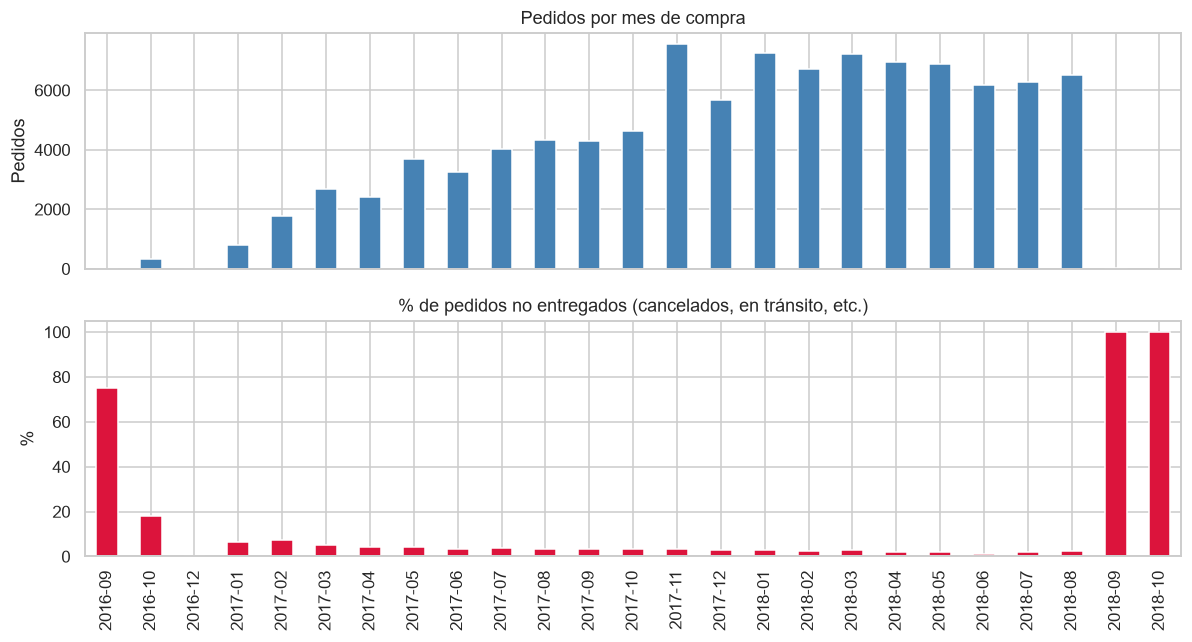

In [10]:
monthly_all = orders.groupby(orders.order_purchase_timestamp.dt.to_period("M")).agg(
    pedidos=("order_id", "size"),
    no_entregados=("order_status", lambda s: (s != "delivered").mean()),
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
monthly_all["pedidos"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title="Pedidos por mes de compra", ylabel="Pedidos")
monthly_all["no_entregados"].mul(100).plot(kind="bar", ax=axes[1], color="crimson")
axes[1].set(title="% de pedidos no entregados (cancelados, en tránsito, etc.)", ylabel="%", xlabel="")
plt.tight_layout(); plt.show()

**Insights:**
- 2016 tiene muy pocos pedidos (fase de arranque de la plataforma) y un mes sin datos (nov-2016).
- Septiembre y octubre de 2018 tienen apenas unas decenas de pedidos y **ninguno entregado**: es el corte del dataset. Esos pedidos están **censurados** (no sabemos si llegarían tarde).
- Entre 2017 y agosto 2018 el porcentaje de pedidos no entregados es bajo (~1–7 %) y no crece al final, así que excluirlos no sesga el objetivo.
- El volumen crece fuerte durante 2017 y se estabiliza en 2018 → la plataforma cambió de escala, otro indicio de que el comportamiento puede variar en el tiempo.

**Decisión:** trabajar con compras entre **enero 2017 y agosto 2018**.

In [11]:
df = df[(df.order_purchase_timestamp >= "2017-01-01") & (df.order_purchase_timestamp < "2018-09-01")].copy()
print(f"Pedidos para modelado: {len(df):,}")

Pedidos para modelado: 96,183


### 5.2 Variable objetivo: entregas tardías y su evolución

Tasa global de retraso: 6.79%


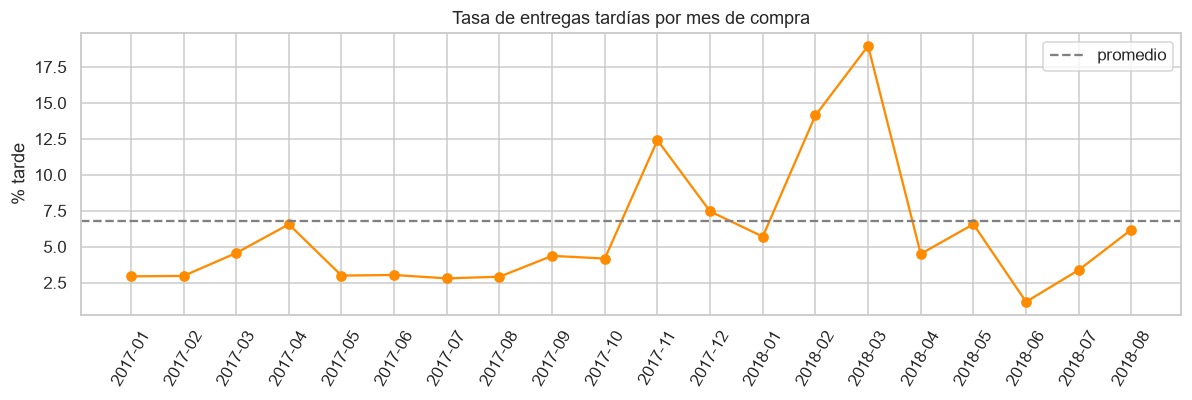

In [12]:
monthly = df.groupby("purchase_month").agg(late_rate=("late", "mean"), pedidos=("order_id", "size"))
print(f"Tasa global de retraso: {df.late.mean():.2%}")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(monthly.index.astype(str), monthly.late_rate * 100, marker="o", color="darkorange")
ax.axhline(df.late.mean() * 100, ls="--", color="gray", label="promedio")
ax.set(title="Tasa de entregas tardías por mes de compra", ylabel="% tarde")
ax.tick_params(axis="x", rotation=60); ax.legend()
plt.tight_layout(); plt.show()

**Insights:**
- Clases **desbalanceadas**: solo ~7 % de pedidos llega tarde → la exactitud (accuracy) no sirve como métrica; se usarán PR-AUC, recall y precisión (sección 11), y se evaluará **data augmentation** (SMOTENC / CTGAN) frente a `class_weight`.
- La tasa de retraso **no es estable**: hay picos en noviembre 2017 (Black Friday) y febrero–marzo 2018. Esto es **deriva (drift)** real y tiene dos consecuencias:
  1. La validación debe ser **temporal** (entrenar con el pasado, evaluar con el futuro), no un `train_test_split` aleatorio.
  2. Justifica la estrategia de reajuste (sección 14) con evidencia de los propios datos.

### 5.3 Retrasos y experiencia del cliente

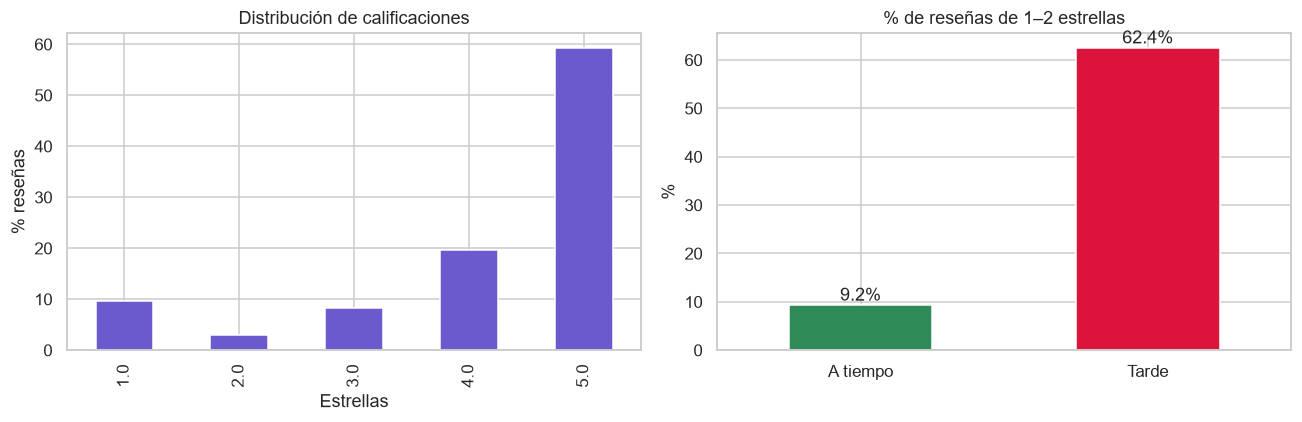

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.review_score.value_counts(normalize=True).sort_index().mul(100).plot(kind="bar", ax=axes[0], color="slateblue")
axes[0].set(title="Distribución de calificaciones", xlabel="Estrellas", ylabel="% reseñas")

bad_by_late = df.groupby("late")["bad_review"].mean().mul(100)
bad_by_late.index = ["A tiempo", "Tarde"]
bad_by_late.plot(kind="bar", ax=axes[1], color=["seagreen", "crimson"])
axes[1].set(title="% de reseñas de 1–2 estrellas", ylabel="%", xlabel="")
axes[1].tick_params(axis="x", rotation=0)
for i, v in enumerate(bad_by_late):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()

**Insight clave para el negocio:** un pedido tardío tiene una probabilidad mucho mayor de recibir 1–2 estrellas. Detectar retrasos **antes** de que ocurran es la palanca más directa para proteger la satisfacción. Esto justifica elegir `late` como objetivo principal.

### 5.4 Geografía: dónde se concentran los retrasos

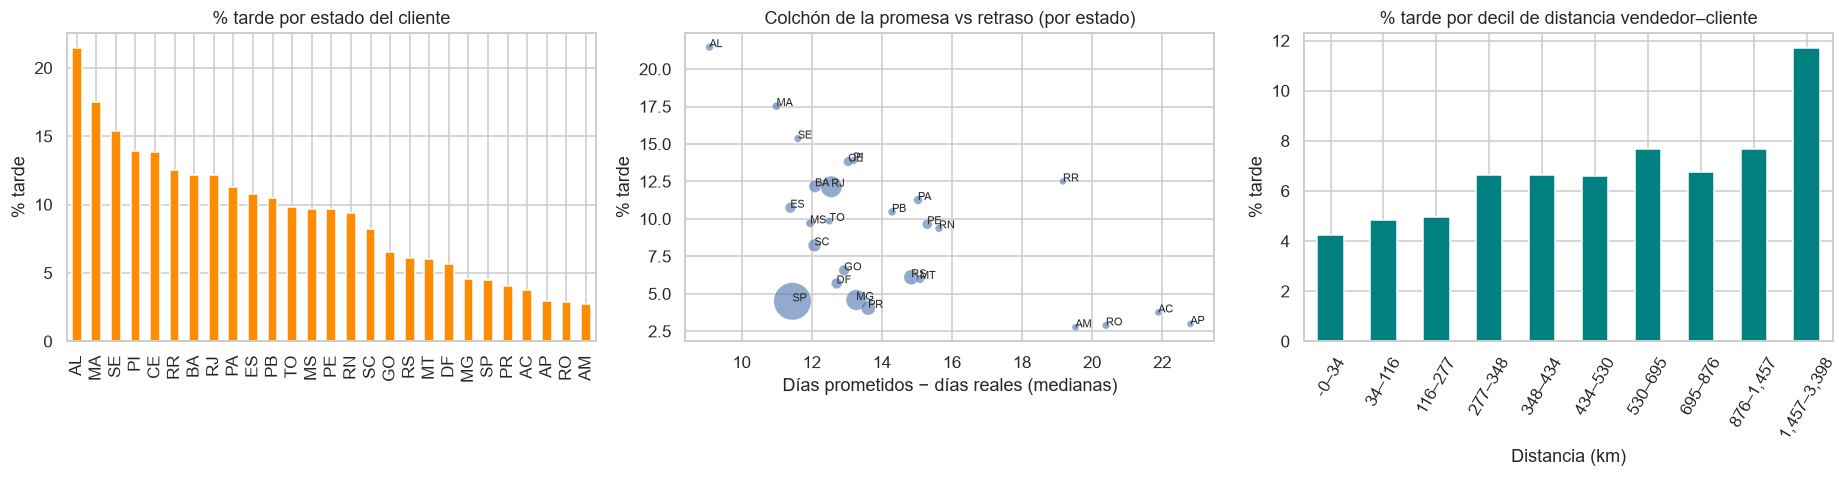

,late_rate,pedidos,distancia_mediana_km,dias_prometidos,dias_reales,colchon_dias
customer_state,,,,,,
AL,0.21,396,1914.98,31.41,22.33,9.08
MA,0.18,713,2196.92,30.18,19.18,11.00
SE,0.15,332,1721.03,29.53,17.93,11.61
PI,0.14,475,2058.40,29.47,16.28,13.19
CE,0.14,1273,2292.53,31.21,18.17,13.04
RR,0.12,40,3302.18,44.30,25.13,19.17
BA,0.12,3253,1422.79,29.01,16.91,12.10
RJ,0.12,12310,394.38,24.59,12.04,12.56
PA,0.11,942,2394.12,36.10,21.07,15.03


In [14]:
by_state = df.groupby("customer_state").agg(
    late_rate=("late", "mean"),
    pedidos=("order_id", "size"),
    distancia_mediana_km=("distance_km", "median"),
    dias_prometidos=("promised_days", "median"),
    dias_reales=("delivery_days", "median"),
)
by_state["colchon_dias"] = by_state.dias_prometidos - by_state.dias_reales
by_state = by_state.sort_values("late_rate", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
by_state["late_rate"].mul(100).plot(kind="bar", ax=axes[0], color="darkorange")
axes[0].set(title="% tarde por estado del cliente", ylabel="% tarde", xlabel="")

sns.scatterplot(data=by_state, x="colchon_dias", y=by_state.late_rate * 100, size="pedidos",
                sizes=(20, 600), alpha=.6, legend=False, ax=axes[1])
for state, row in by_state.iterrows():
    axes[1].annotate(state, (row.colchon_dias, row.late_rate * 100), fontsize=7)
axes[1].set(title="Colchón de la promesa vs retraso (por estado)",
            xlabel="Días prometidos − días reales (medianas)", ylabel="% tarde")

deciles = pd.qcut(df.distance_km, 10)
late_by_dist = df.groupby(deciles, observed=True)["late"].mean().mul(100)
late_by_dist.index = [f"{i.left:,.0f}–{i.right:,.0f}" for i in late_by_dist.index]
late_by_dist.plot(kind="bar", ax=axes[2], color="teal")
axes[2].set(title="% tarde por decil de distancia vendedor–cliente", ylabel="% tarde", xlabel="Distancia (km)")
axes[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
by_state.round(2).head(10)

**Insights:**
- Los estados del **nordeste** (AL, MA, SE, PI, CE, BA) tienen las tasas de retraso más altas. Pero los estados más remotos del **norte** (AM, RO, AP) tienen tasas **bajas**, aunque están más lejos.
- La explicación está en la promesa: para esos estados la fecha estimada trae un **colchón** enorme (se prometen ~45 días y se entrega en ~25). El retraso no depende solo de la distancia sino de **qué tan realista es la fecha prometida**. Por eso `promised_days` debe entrar al modelo junto con la distancia.
- **Rio de Janeiro** (RJ) es un caso atípico: está cerca de São Paulo y aun así tiene ~12 % de retrasos → la logística local importa, no solo la distancia.
- Por distancia, el retraso es estable (~5–7 %) hasta los ~1,500 km y se dispara en el último decil. La distancia (calculada con Haversine desde la tabla de geolocalización) es una variable **construida** que no venía explícita en los datos.
- Hay estados con muy pocos pedidos (p. ej. RR, AP): al codificarlos conviene agrupar categorías raras.

### 5.5 Precio, flete y peso: distribuciones y atípicos

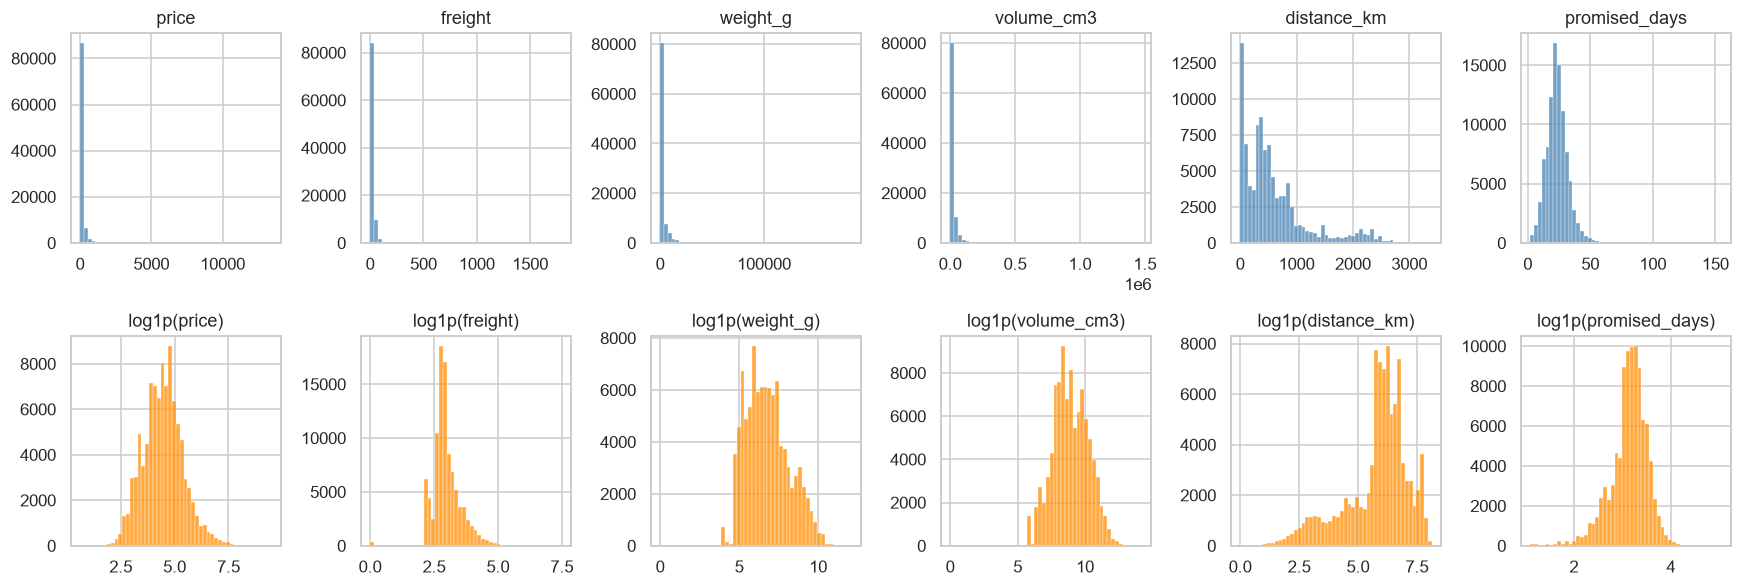

,count,mean,std,min,1%,50%,99%,max,skew
price,96183.0,136.99,209.14,0.85,11.99,86.40,992.46,13440.00,9.90
freight,96183.0,22.78,21.56,0.00,7.39,17.17,104.23,1794.96,12.30
weight_g,96183.0,2385.29,4770.31,0.00,90.00,750.00,22350.00,184400.00,6.58
volume_cm3,96183.0,17315.98,30146.49,0.00,352.00,7224.00,135594.00,1476000.00,7.37
distance_km,95704.0,600.36,592.30,0.00,5.75,433.81,2482.44,3398.49,1.66
promised_days,96183.0,23.65,8.60,2.01,6.04,23.22,48.24,155.14,0.83


In [15]:
num_cols = ["price", "freight", "weight_g", "volume_cm3", "distance_km", "promised_days"]
fig, axes = plt.subplots(2, len(num_cols), figsize=(16, 5.5))
for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), bins=50, ax=axes[0, i], color="steelblue")
    axes[0, i].set(title=col, xlabel="", ylabel="")
    sns.histplot(np.log1p(df[col].dropna().clip(lower=0)), bins=50, ax=axes[1, i], color="darkorange")
    axes[1, i].set(title=f"log1p({col})", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

desc = df[num_cols].describe(percentiles=[.01, .5, .99]).T
desc["skew"] = df[num_cols].skew()
desc.round(2)

**Insights:**
- Precio, flete, peso y volumen tienen **sesgo fuerte a la derecha** (asimetría entre 6 y 12). La transformación `log1p` las vuelve aproximadamente simétricas → importante para modelos basados en distancias (kNN, SVM, K-Means), no tanto para árboles.
- `distance_km` y `promised_days` tienen sesgo moderado: el logaritmo **sobrecorrige** la distancia (queda sesgada a la izquierda), así que esas dos solo se escalan.
- Los valores extremos (p. ej. pedidos de miles de reales o fletes muy altos) son **plausibles** (productos caros o voluminosos), no errores: se conservan y se usa escalado robusto/log en vez de eliminarlos.

### 5.6 ¿Por qué no segmentar clientes?

In [16]:
orders_per_customer = df.groupby("customer_unique_id").size()
print(f"Clientes únicos: {len(orders_per_customer):,}")
print(f"Clientes con más de un pedido: {(orders_per_customer > 1).mean():.2%}")
orders_per_customer.value_counts().head(5).rename("clientes").to_frame()

Clientes únicos: 93,079
Clientes con más de un pedido: 2.99%


,clientes
1,90293
2,2559
3,180
4,28
5,9


**Insight:** casi todos los clientes compran una sola vez. Una segmentación RFM (recencia, frecuencia, valor) no tendría variación en "frecuencia" y sería poco informativa. Los **vendedores**, en cambio, tienen historial (muchos pedidos cada uno) → son la unidad natural para la fase no supervisada.

### 5.7 Vendedores: concentración y comportamiento

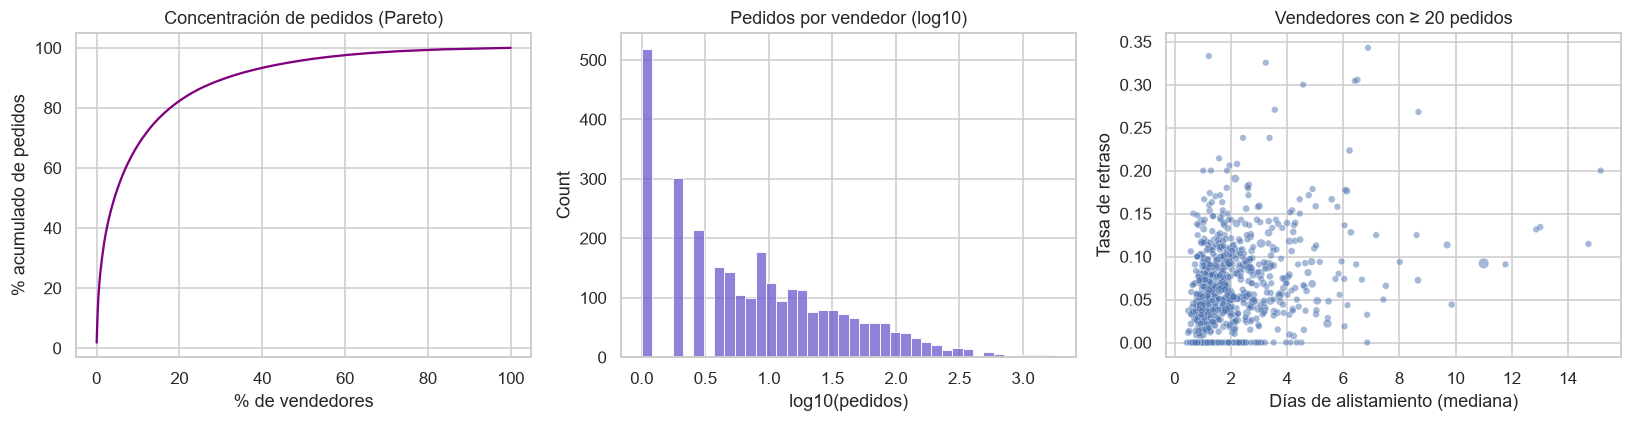

Vendedores: 2,935 | 20 % de vendedores concentra 82% de los pedidos


In [17]:
seller_stats = df.groupby("seller_id").agg(
    pedidos=("order_id", "size"),
    late_rate=("late", "mean"),
    bad_rate=("bad_review", "mean"),
    handling_mediana=("handling_days", "median"),
)
share = seller_stats.pedidos.sort_values(ascending=False).cumsum() / seller_stats.pedidos.sum()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(np.arange(1, len(share) + 1) / len(share) * 100, share.values * 100, color="purple")
axes[0].set(title="Concentración de pedidos (Pareto)", xlabel="% de vendedores", ylabel="% acumulado de pedidos")
sns.histplot(np.log10(seller_stats.pedidos), bins=40, ax=axes[1], color="slateblue")
axes[1].set(title="Pedidos por vendedor (log10)", xlabel="log10(pedidos)")
active = seller_stats[seller_stats.pedidos >= 20]
sns.scatterplot(data=active, x="handling_mediana", y="late_rate", size="pedidos", alpha=.5, ax=axes[2], legend=False)
axes[2].set(title="Vendedores con ≥ 20 pedidos", xlabel="Días de alistamiento (mediana)", ylabel="Tasa de retraso")
plt.tight_layout(); plt.show()
print(f"Vendedores: {len(seller_stats):,} | 20 % de vendedores concentra {share.iloc[int(len(share)*.2)]:.0%} de los pedidos")

**Insights:**
- Pocos vendedores concentran la mayoría de pedidos; muchos tienen muy pocos → para la segmentación se exigirá un **mínimo de pedidos** por vendedor (las tasas de un vendedor con 2 pedidos no son confiables).
- Los vendedores que tardan más en alistar (más días entre aprobación y despacho) tienden a tener más retrasos. Hay perfiles operativos distintos → buena señal de que la segmentación tendrá sentido.

### 5.8 La variable más informativa al momento del despacho: el margen restante

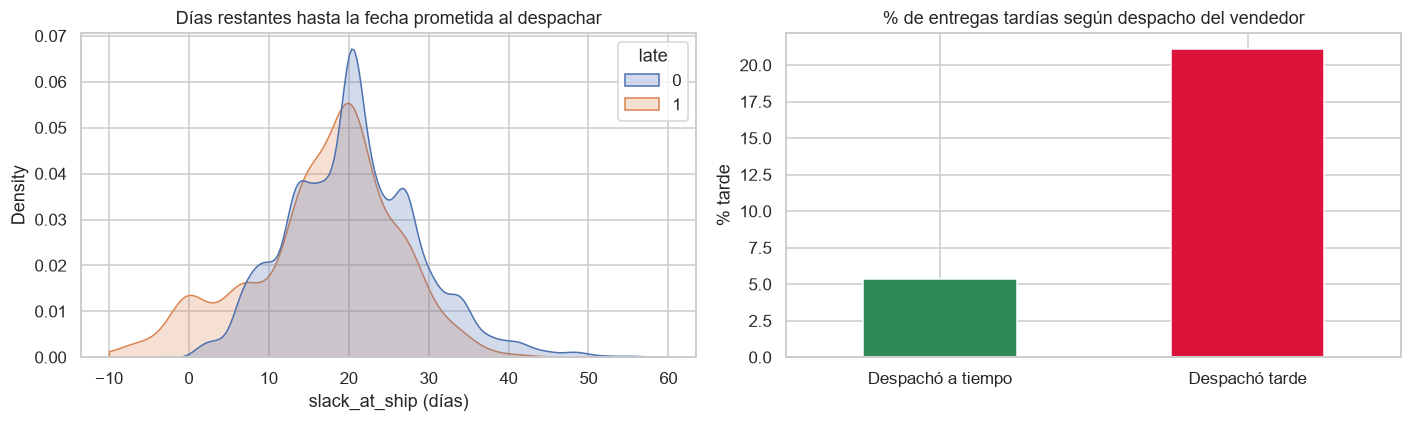

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=df, x="slack_at_ship", hue="late", common_norm=False, fill=True, ax=axes[0], clip=(-10, 60))
axes[0].set(title="Días restantes hasta la fecha prometida al despachar", xlabel="slack_at_ship (días)")

df.groupby("shipped_after_limit")["late"].mean().mul(100).rename({0: "Despachó a tiempo", 1: "Despachó tarde"}).plot(
    kind="bar", ax=axes[1], color=["seagreen", "crimson"])
axes[1].set(title="% de entregas tardías según despacho del vendedor", ylabel="% tarde", xlabel="")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Insight:** cuando el vendedor despacha, ya se sabe cuánto margen queda hasta la fecha prometida y si incumplió el plazo de despacho (`shipping_limit_date`). La distribución de los pedidos tardíos tiene una cola clara hacia márgenes pequeños o negativos, y despachar después del plazo multiplica por ~4 la tasa de retraso. Esto define el **momento de predicción** (sección 6): al despachar, el modelo tiene información útil y todavía hay tiempo de actuar.

### 5.9 Correlaciones entre variables numéricas

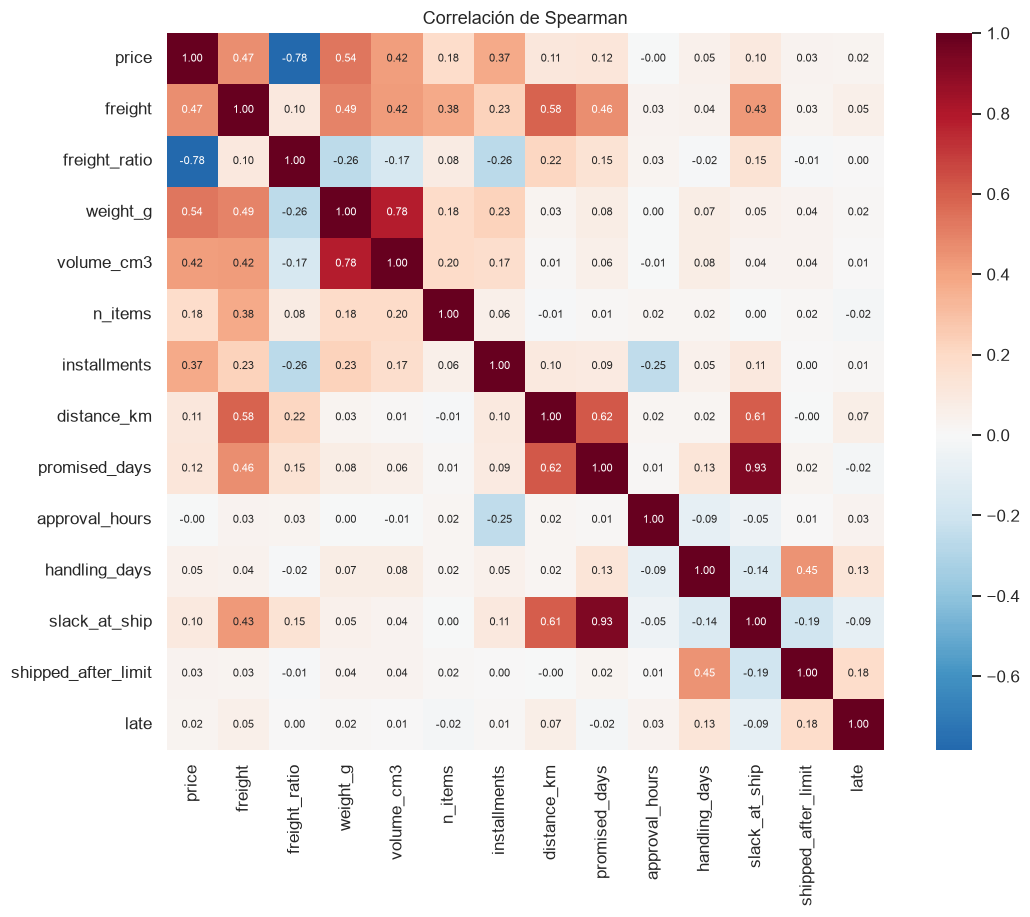

In [19]:
corr_cols = ["price", "freight", "freight_ratio", "weight_g", "volume_cm3", "n_items", "installments",
             "distance_km", "promised_days", "approval_hours", "handling_days", "slack_at_ship",
             "shipped_after_limit", "late"]
corr = df[corr_cols].corr(method="spearman")
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
plt.title("Correlación de Spearman")
plt.tight_layout(); plt.show()

**Insights:**
- Se usa Spearman porque las variables son asimétricas y la relación con el objetivo no tiene por qué ser lineal.
- Pares muy redundantes: `promised_days`–`slack_at_ship` (0.93), `weight_g`–`volume_cm3` (0.78), `price`–`freight_ratio` (−0.78) y `distance_km`–`promised_days` (0.62) → candidatos a PCA o a quedarse con una variable de cada par en los modelos sensibles a colinealidad (kNN, SVM).
- Las variables más asociadas al retraso son las del despacho (`shipped_after_limit` 0.18, `handling_days` 0.13, `slack_at_ship` −0.09), pero todas son débiles por sí solas: hace falta un modelo que las combine. Esto confirma que el momento de despacho es el adecuado para predecir.

### 5.10 Variables de contexto: ¿tienen señal?

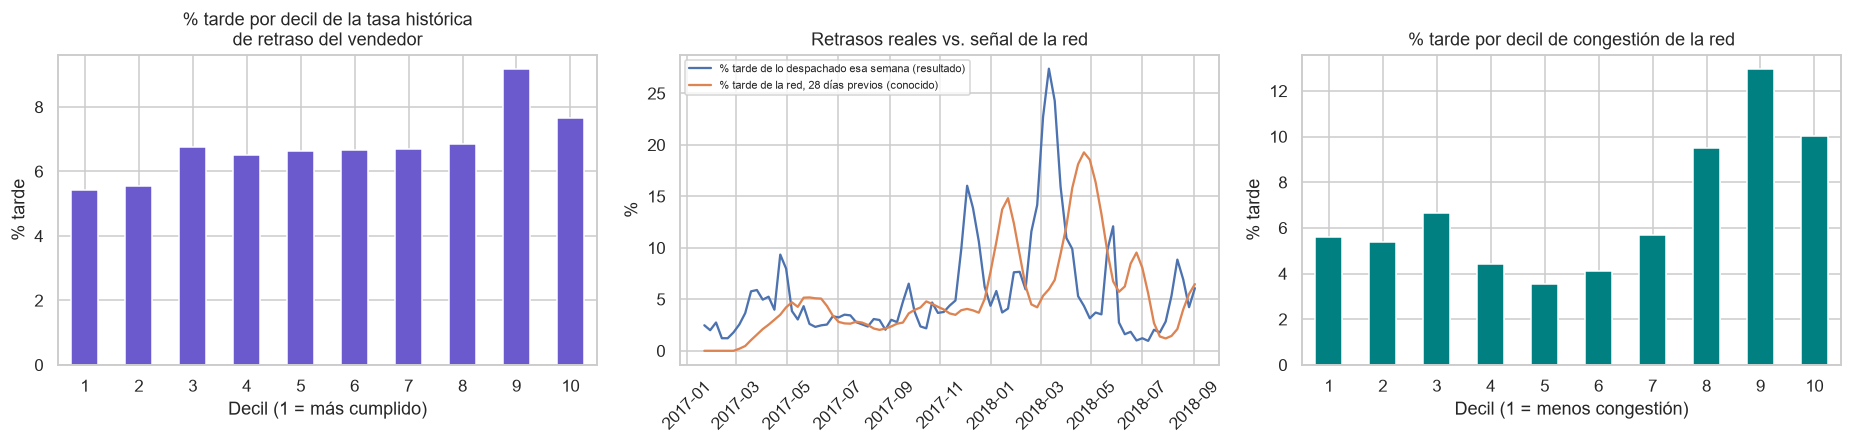

,Spearman con late
seller_late_rate,0.031
seller_bad_rate,0.026
seller_handling_mean,0.070
seller_log_orders,0.024
net_late_rate_28d,0.032
net_backlog_ratio,0.078


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
dec = pd.qcut(df.seller_late_rate, 10, labels=range(1, 11), duplicates="drop")
df.groupby(dec, observed=True).late.mean().mul(100).plot(kind="bar", ax=axes[0], color="slateblue")
axes[0].set(title="% tarde por decil de la tasa histórica\nde retraso del vendedor", xlabel="Decil (1 = más cumplido)",
            ylabel="% tarde")
axes[0].tick_params(axis="x", rotation=0)

weekly = df.set_index("order_delivered_carrier_date").resample("W").agg(
    {"late": "mean", "net_late_rate_28d": "mean", "order_id": "size"})
weekly = weekly[weekly.order_id >= 100][["late", "net_late_rate_28d"]].mul(100)  # semanas con volumen suficiente
axes[1].plot(weekly.index, weekly.late, label="% tarde de lo despachado esa semana (resultado)")
axes[1].plot(weekly.index, weekly.net_late_rate_28d, label="% tarde de la red, 28 días previos (conocido)")
axes[1].set(title="Retrasos reales vs. señal de la red", ylabel="%")
axes[1].legend(fontsize=7)
axes[1].tick_params(axis="x", rotation=45)

dec_b = pd.qcut(df.net_backlog_ratio, 10, labels=range(1, 11), duplicates="drop")
df.groupby(dec_b, observed=True).late.mean().mul(100).plot(kind="bar", ax=axes[2], color="teal")
axes[2].set(title="% tarde por decil de congestión de la red", xlabel="Decil (1 = menos congestión)", ylabel="% tarde")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

df[["seller_late_rate", "seller_bad_rate", "seller_handling_mean", "seller_log_orders", "net_late_rate_28d",
    "net_backlog_ratio", "late"]].corr(method="spearman")["late"].drop("late").round(3).to_frame("Spearman con late")

**Insights:**
- **Historial del vendedor:** hay un gradiente, pero suave: el décil más cumplido tiene ~5.5 % de retrasos y los más incumplidos ~8–9 %. La correlación de Spearman con `late` es apenas 0.03. El pasado del vendedor explica poco del retraso de un pedido concreto; lo que pasa en el despacho (5.8) pesa más.
- **Congestión de la red:** la tasa de retrasos de los últimos 28 días sigue a la real, pero **con rezago**: sube cuando el pico ya está pasando (feb–mar 2018), porque solo se conoce el resultado de los pedidos ya entregados. Como señal anticipada llega tarde.
- **Pedidos en tránsito:** los tres déciles de mayor congestión tienen 10–13 % de retrasos frente a ~5 % del resto: es la señal de contexto más fuerte (Spearman 0.08). Pero está muy ligada a fechas concretas (picos de temporada), así que puede no repetirse igual en el futuro.
- **Decisión:** estas variables tienen algo de señal y no tienen fuga, así que se prueban en el modelo, pero la decisión de usarlas se toma con validación cruzada temporal (9.3), no con estas gráficas.

### 5.11 Resumen de insights → decisiones

| Insight del EDA | Decisión que tomamos |
|---|---|
| 2016 casi vacío; sep–oct 2018 censurados (sin entregas) | Usar ene-2017 a ago-2018 |
| ~7 % de pedidos tardíos (desbalance) | Métricas PR-AUC / recall; comparar `class_weight`, submuestreo, SMOTENC y CTGAN (9.4) |
| Tasa de retraso varía por mes (picos Black Friday, feb–mar 2018) | Validación **temporal** y reajuste basado en monitoreo de deriva (14) |
| Retraso multiplica las reseñas de 1–2 estrellas | Objetivo `late`; `bad_review` para medir impacto (11) |
| ~97 % de clientes compra una sola vez | Segmentar **vendedores**, no clientes (8) |
| Vendedores con perfiles operativos distintos y muy concentrados | Perfil con mínimo de 20 pedidos; K-Means / jerárquico / DBSCAN (8) |
| El retraso depende de la distancia **y** del colchón de la promesa | `distance_km` (construida) y `promised_days`; agrupar estados raros (7) |
| Variables monetarias y físicas muy sesgadas, con atípicos plausibles | `log1p` + recorte de extremos + escalado; no se eliminan filas (7) |
| Margen al despachar muy informativo | Momento de predicción = despacho del vendedor (6) |
| Historial del vendedor y congestión tienen señal, pero menor que la del despacho | Se prueban como variables y se decide con validación (9.3) |

## 6. Fuga de información y momento de predicción (3.6)

Un modelo solo puede usar lo que **ya se conoce en el momento de decidir**. Clasificamos cada variable según cuándo está disponible:

| Momento | Variables | ¿Se pueden usar? |
|---|---|---|
| Compra | productos, precio, flete, peso, categoría, pago, cuotas, estado y ubicación del cliente y vendedor, `distance_km`, `promised_days` | ✅ |
| Aprobación | `approval_hours` | ✅ |
| **Despacho (momento de predicción)** | `handling_days`, `slack_at_ship`, `limit_margin_days`, `shipped_after_limit`, `ship_dow` | ✅ |
| Contexto antes del despacho | perfil del vendedor y congestión de la red (4.1), segmento del vendedor (8) | ✅ (calculados solo con el pasado) |
| Entrega | `order_delivered_customer_date`, `delivery_days`, `delay_days` | ❌ definen el objetivo |
| Reseña | `review_score`, comentarios, `bad_review` | ❌ ocurren después |

**Partición temporal.** Por la deriva observada en 5.2, el split nunca es aleatorio:

- **Entrenamiento:** compras de ene-2017 a feb-2018. Aquí se hace toda la validación cruzada y la selección de modelos.
- **Brecha:** compras de mar–abr 2018. Simula que el modelo se entrena el 1 de mayo de 2018: en ese momento muchos de esos pedidos aún no se habían entregado (y los que sí, son sesgadamente los rápidos), así que no se usan para entrenar.
- **Prueba:** compras de may–ago 2018. Se usa **una sola vez**, en la sección 10.

**Otras fugas que se controlan:** el preprocesamiento y el data augmentation van dentro de un `Pipeline` que se ajusta solo en los folds de entrenamiento; la segmentación se entrena con la foto de vendedores al 1-may-2018 (sección 8).

In [21]:
LEAKY = ["order_delivered_customer_date", "delivery_days", "delay_days", "review_score",
         "review_creation_date", "review_answer_timestamp", "review_comment_message", "bad_review"]


def split(data):
    tr = data[data.order_purchase_timestamp < TRAIN_END].sort_values("order_purchase_timestamp").reset_index(drop=True)
    te = data[data.order_purchase_timestamp >= TEST_START].sort_values("order_purchase_timestamp").reset_index(drop=True)
    return tr, te


train, test = split(df)
gap = df[(df.order_purchase_timestamp >= TRAIN_END) & (df.order_purchase_timestamp < TEST_START)]
pd.DataFrame({
    "pedidos": [len(train), len(gap), len(test)],
    "tasa_tarde": [train.late.mean(), gap.late.mean(), test.late.mean()],
    "compra_desde": [train.order_purchase_timestamp.min().date(), TRAIN_END.date(), TEST_START.date()],
    "compra_hasta": [train.order_purchase_timestamp.max().date(), gap.order_purchase_timestamp.max().date(),
                     test.order_purchase_timestamp.max().date()],
    "% entregado antes del 1-may-2018": [(train.order_delivered_customer_date < TEST_START).mean(),
                                         (gap.order_delivered_customer_date < TEST_START).mean(), 0.0],
}, index=["entrenamiento", "brecha (no se usa)", "prueba"]).round(4)

,pedidos,tasa_tarde,compra_desde,compra_hasta,% entregado antes del 1-may-2018
entrenamiento,57030,0.0663,2017-01-05,2018-02-28,0.9993
brecha (no se usa),13801,0.1184,2018-03-01,2018-04-30,0.7999
prueba,25352,0.0440,2018-05-01,2018-08-29,0.0000


## 7. Preprocesamiento (3.2)

Todo el preprocesamiento va en un `ColumnTransformer` dentro del `Pipeline` del modelo, de modo que en la validación cruzada se ajusta **solo con el fold de entrenamiento** (sin fuga) y en producción se aplica idéntico.

| Paso | Variables | Por qué (evidencia) |
|---|---|---|
| Imputación por **mediana** | `approval_hours` (0.16 % nulos), medidas y fotos del producto (≈1.9 %), `distance_km` (prefijos sin coordenadas), perfil del vendedor (vendedor sin historial) | La mediana es robusta al sesgo fuerte visto en 5.5; los nulos son pocos y estructurales |
| Imputación por **moda** | categóricas | Muy pocos nulos |
| `log1p` | precio, flete, peso, volumen, descripción, horas de aprobación | Asimetría de 6 a 12 (5.5); el log las vuelve casi simétricas |
| **Recorte** de extremos al percentil 0.5–99.5 | numéricas | Los atípicos son plausibles (5.5), así que **no se borran filas**; solo se limita su peso en modelos basados en distancias |
| `StandardScaler` | numéricas | kNN, SVM y K-Means usan distancias: sin escalar dominaría la variable de mayor rango. Para los árboles es inocuo (son invariantes a transformaciones monótonas) |
| `OneHotEncoder(min_frequency=300)` | estado del cliente y del vendedor, categoría, medio de pago | Los estados y categorías raros (5.4) se agrupan en "infrequent"; `handle_unknown` evita fallos si en producción aparece una categoría nueva |

**Variables excluidas:** identificadores, fechas crudas, variables con fuga (sección 6), `days_to_ship` (= aprobación + alistamiento, redundante), `n_payments` y el código postal (alta cardinalidad: la geografía ya entra por estado y distancia).

19 numéricas + 4 categóricas → 76 columnas después del preprocesamiento
Categorías agrupadas como 'infrequent': {'customer_state': 10, 'seller_state': 14, 'category': 48}


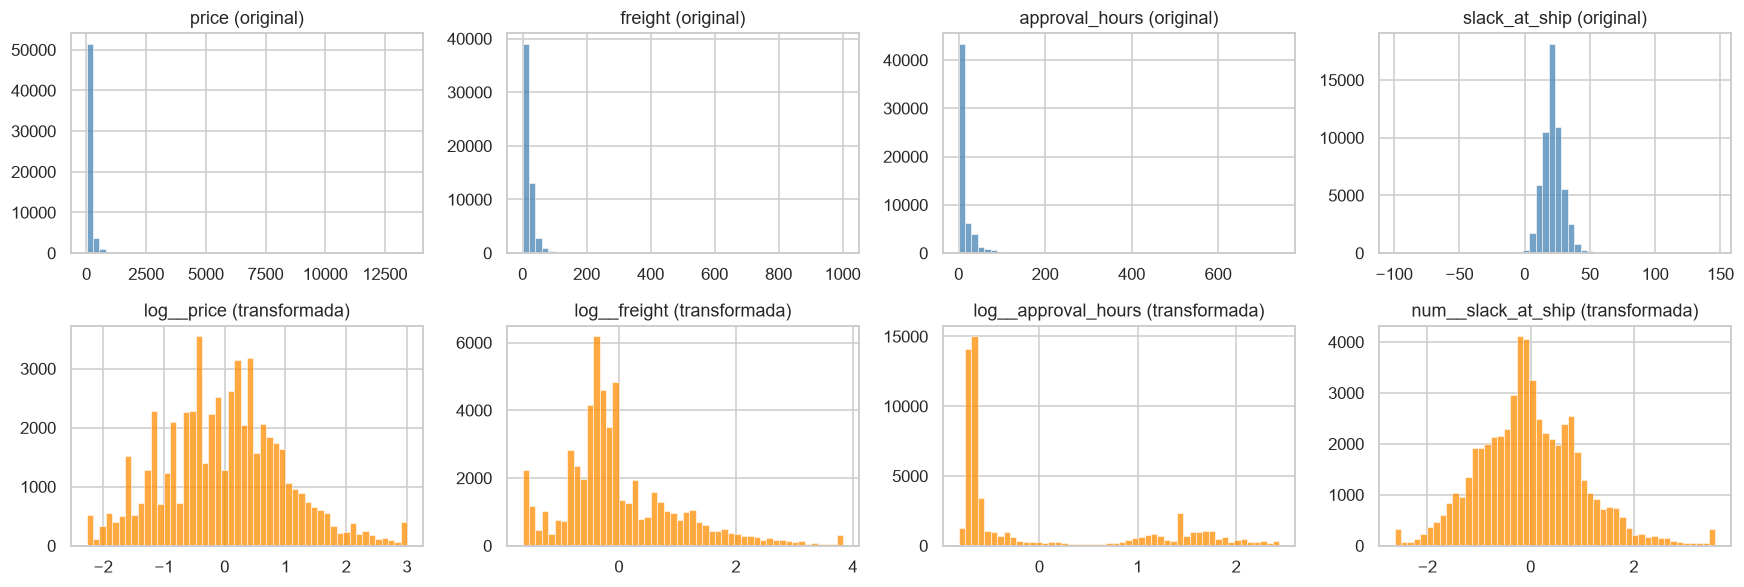

In [22]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

NET = ["net_late_rate_28d", "net_backlog_ratio"]
SELLER = ml.SELLER_PROFILE
BASE_NUM = [c for c in ml.NUMERIC if c not in SELLER + NET]
CAT = ml.CATEGORICAL


def numeric_pipeline(log):
    steps = [("imputar", SimpleImputer(strategy="median"))]
    if log:
        steps.append(("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
    return Pipeline(steps + [("recortar", ml.Winsorizer(0.005, 0.995)), ("escalar", StandardScaler())])


def make_preprocessor(num, cat=CAT):
    return ColumnTransformer([
        ("log", numeric_pipeline(True), [c for c in num if c in ml.SKEWED]),
        ("num", numeric_pipeline(False), [c for c in num if c not in ml.SKEWED]),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=300,
                                                   sparse_output=False))]), cat),
    ])


pre = make_preprocessor(BASE_NUM).fit(train)
Xt = pd.DataFrame(pre.transform(train), columns=pre.get_feature_names_out())
print(f"{len(BASE_NUM)} numéricas + {len(CAT)} categóricas → {Xt.shape[1]} columnas después del preprocesamiento")
print("Categorías agrupadas como 'infrequent':",
      {c: len(v) for c, v in zip(CAT, pre.named_transformers_["cat"]["onehot"].infrequent_categories_) if v is not None})

fig, axes = plt.subplots(2, 4, figsize=(16, 5.5))
for i, col in enumerate(["price", "freight", "approval_hours", "slack_at_ship"]):
    sns.histplot(train[col].dropna(), bins=50, ax=axes[0, i], color="steelblue")
    axes[0, i].set(title=f"{col} (original)", xlabel="", ylabel="")
    tcol = next(n for n in Xt.columns if n.endswith("__" + col))
    sns.histplot(Xt[tcol], bins=50, ax=axes[1, i], color="darkorange")
    axes[1, i].set(title=f"{tcol} (transformada)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

**Lectura:** después del preprocesamiento las variables monetarias quedan casi simétricas y en la misma escala que el resto; los estados y categorías con menos de 300 pedidos en entrenamiento se agrupan en una sola columna "infrequent".

## 8. Fase no supervisada: segmentación de vendedores (3.4)

**Objetivo:** encontrar perfiles operativos de vendedores que (a) le sirvan al equipo de operaciones para decidir a quién acompañar y (b) puedan aportar información al modelo de retrasos.

### 8.1 Perfil de cada vendedor

Se toma la **foto de los vendedores al 1 de mayo de 2018** (fecha en que se entrena el modelo): solo pedidos ya entregados y reseñas ya respondidas antes de esa fecha. Se exigen **al menos 20 pedidos entregados**: con menos, las tasas son ruido (5.7).

Vendedores con historial al 2018-05-01: 2,229 | con ≥ 20 pedidos entregados: 611 (88% de los pedidos)


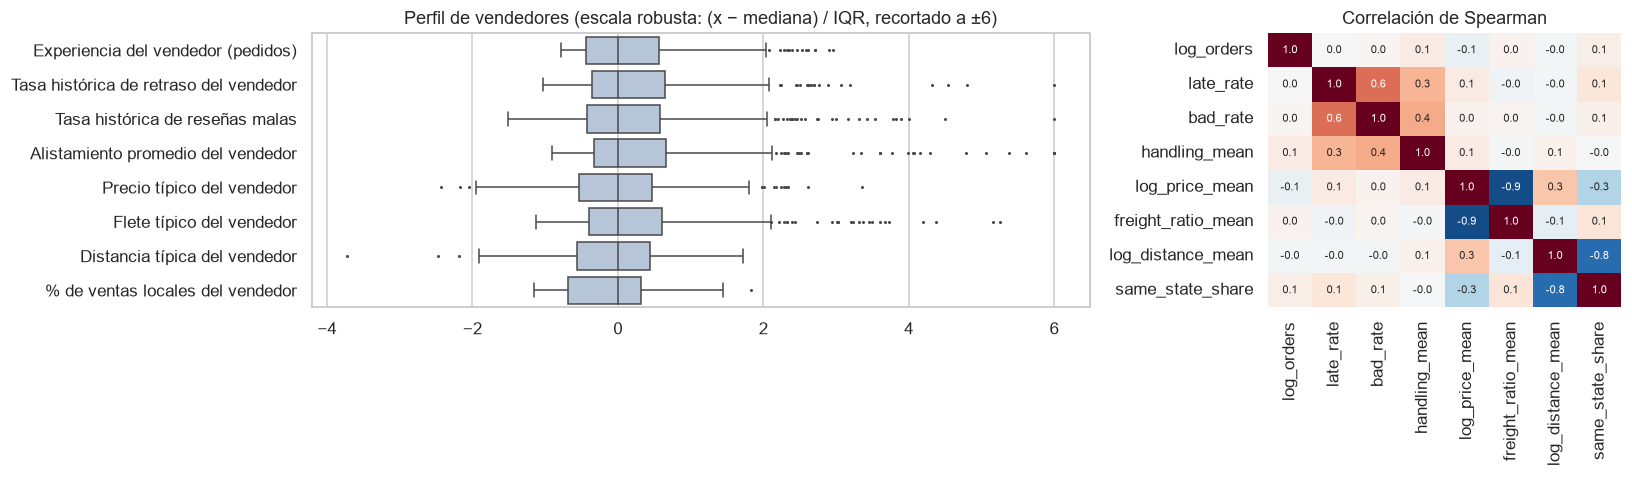

,count,mean,std,min,25%,50%,75%,max
seller_log_orders,611.0,4.105,0.856,3.045,3.434,3.932,4.575,7.311
seller_late_rate,611.0,0.069,0.041,0.010,0.041,0.058,0.088,0.359
seller_bad_rate,611.0,0.133,0.055,0.036,0.099,0.123,0.156,0.529
seller_handling_mean,611.0,2.894,2.061,0.675,1.683,2.271,3.448,21.118
seller_log_price_mean,611.0,4.483,0.683,2.397,4.026,4.478,4.883,7.357
seller_freight_ratio_mean,611.0,0.309,0.195,0.021,0.177,0.260,0.389,1.377
seller_log_distance_mean,611.0,5.836,0.571,2.723,5.420,5.896,6.272,7.367
seller_same_state_share,611.0,0.323,0.182,0.000,0.148,0.364,0.462,0.938


In [23]:
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

snap = ml.seller_snapshot(df, TEST_START, PRIOR_LATE, PRIOR_BAD)
active = snap[snap.seller_known_orders >= ml.MIN_ORDERS_SEGMENT].dropna(subset=SELLER).copy()
print(f"Vendedores con historial al {TEST_START.date()}: {len(snap):,} | "
      f"con ≥ {ml.MIN_ORDERS_SEGMENT} pedidos entregados: {len(active):,} "
      f"({active.seller_known_orders.sum() / snap.seller_known_orders.sum():.0%} de los pedidos)")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
z =(active[SELLER] - active[SELLER].median()) / (active[SELLER].quantile(.75) - active[SELLER].quantile(.25))
sns.boxplot(data=z.clip(-6, 6).rename(columns=ml.LABELS), orient="h", ax=axes[0], fliersize=1, color="lightsteelblue")
axes[0].set(title="Perfil de vendedores (escala robusta: (x − mediana) / IQR, recortado a ±6)", xlabel="")
sns.heatmap(active[SELLER].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=axes[1], cbar=False,
            xticklabels=[s.replace("seller_", "") for s in SELLER], yticklabels=[s.replace("seller_", "") for s in SELLER])
axes[1].set(title="Correlación de Spearman")
plt.tight_layout(); plt.show()
active[SELLER].describe().T.round(3)

**Lectura:** hay variables con colas largas (alistamiento promedio, relación flete/precio) y correlaciones moderadas (tasa de retraso ↔ reseñas malas ↔ alistamiento). Por eso se **recortan los extremos al percentil 1–99** y se **estandariza** antes de agrupar: K-Means y DBSCAN usan distancia euclidiana y, sin esto, un puñado de vendedores atípicos definiría los grupos.

### 8.2 K-Means: ¿cuántos segmentos?

Se comparan k = 2…10 con cuatro criterios: inercia (codo), silhouette (separación, más alto mejor), Davies-Bouldin (más bajo mejor) y **estabilidad** (ARI entre la segmentación completa y la de 10 submuestras del 80 %: si los grupos cambian al quitar vendedores, no son confiables).

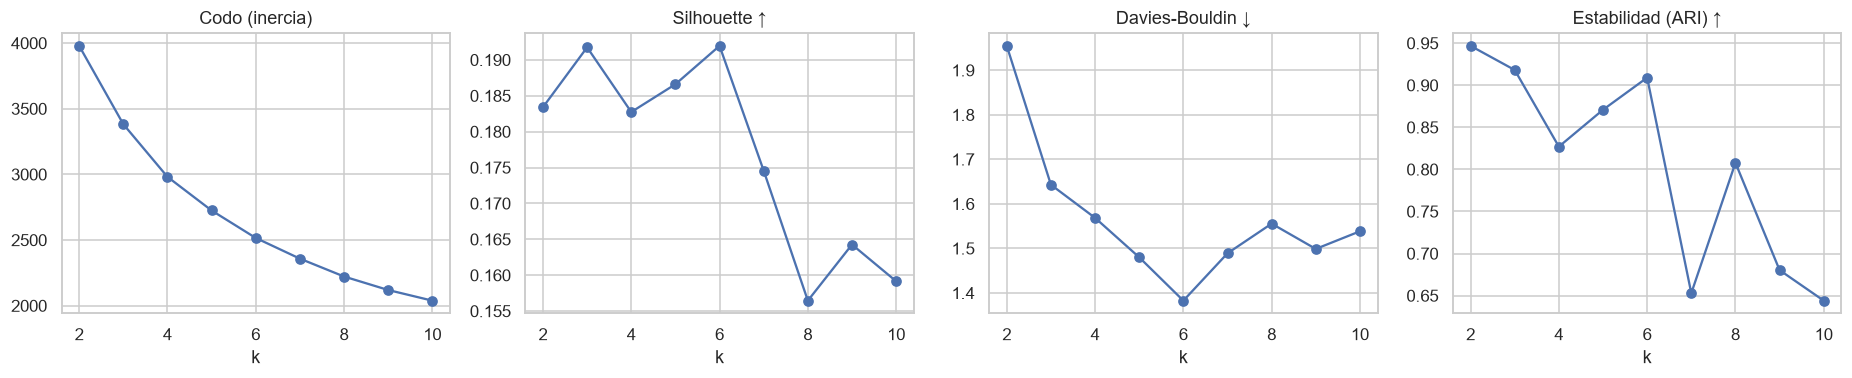

,inercia,silhouette,davies_bouldin,estabilidad_ARI,grupo_mas_pequeño
k,,,,,
2,3978.559,0.183,1.955,0.947,300
3,3381.913,0.192,1.643,0.918,101
4,2980.958,0.183,1.568,0.827,95
5,2724.812,0.187,1.480,0.871,72
6,2515.688,0.192,1.383,0.909,18
7,2357.994,0.175,1.489,0.653,18
8,2221.992,0.156,1.555,0.808,18
9,2119.201,0.164,1.499,0.680,18
10,2038.169,0.159,1.538,0.644,18


In [24]:
seg_pre = Pipeline([("recortar", ml.Winsorizer(0.01, 0.99)), ("escalar", StandardScaler())])
Z = seg_pre.fit_transform(active[SELLER])
rng = np.random.default_rng(RANDOM_STATE)
rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    ari = []
    for b in range(10):
        idx = rng.choice(len(Z), int(0.8 * len(Z)), replace=False)
        ari.append(adjusted_rand_score(km.labels_[idx], KMeans(k, n_init=10, random_state=b).fit_predict(Z[idx])))
    rows.append({"k": k, "inercia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                 "davies_bouldin": davies_bouldin_score(Z, km.labels_), "estabilidad_ARI": np.mean(ari),
                 "grupo_mas_pequeño": np.bincount(km.labels_).min()})
km_scores = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col, title in zip(axes, ["inercia", "silhouette", "davies_bouldin", "estabilidad_ARI"],
                          ["Codo (inercia)", "Silhouette ↑", "Davies-Bouldin ↓", "Estabilidad (ARI) ↑"]):
    ax.plot(km_scores.index, km_scores[col], marker="o")
    ax.set(title=title, xlabel="k")
plt.tight_layout(); plt.show()
km_scores.round(3)

**Decisión de k = 5:**
- El **silhouette es bajo para todo k** (~0.16–0.19): los vendedores no forman grupos muy separados sino un continuo con zonas más densas. Es normal en datos operativos reales, y por eso no se puede elegir k solo con esta métrica.
- El **codo** no es marcado; la inercia baja de forma suave después de k = 3–5.
- **Davies-Bouldin** mejora hasta k = 6, pero en k ≥ 6 aparece un grupo de solo 18 vendedores (los atípicos que DBSCAN aísla en 8.4), y la **estabilidad** cae por debajo de 0.7 desde k = 7.
- **k = 5** combina: segunda mejor estabilidad entre los k con grupos de tamaño útil (ARI ≈ 0.87), grupo más pequeño de 72 vendedores y, sobre todo, segmentos **interpretables** para el negocio (8.6). k = 2–3 serían más estables, pero solo separan "buenos" de "malos", lo que no sirve para decidir acciones distintas.

In [25]:
K_SEG = 5

### 8.3 Clustering jerárquico (aglomerativo)

Se construye el dendrograma con enlace de **Ward** (minimiza la varianza dentro de los grupos, el mismo criterio de K-Means) y se compara con los enlaces *average* y *complete*.

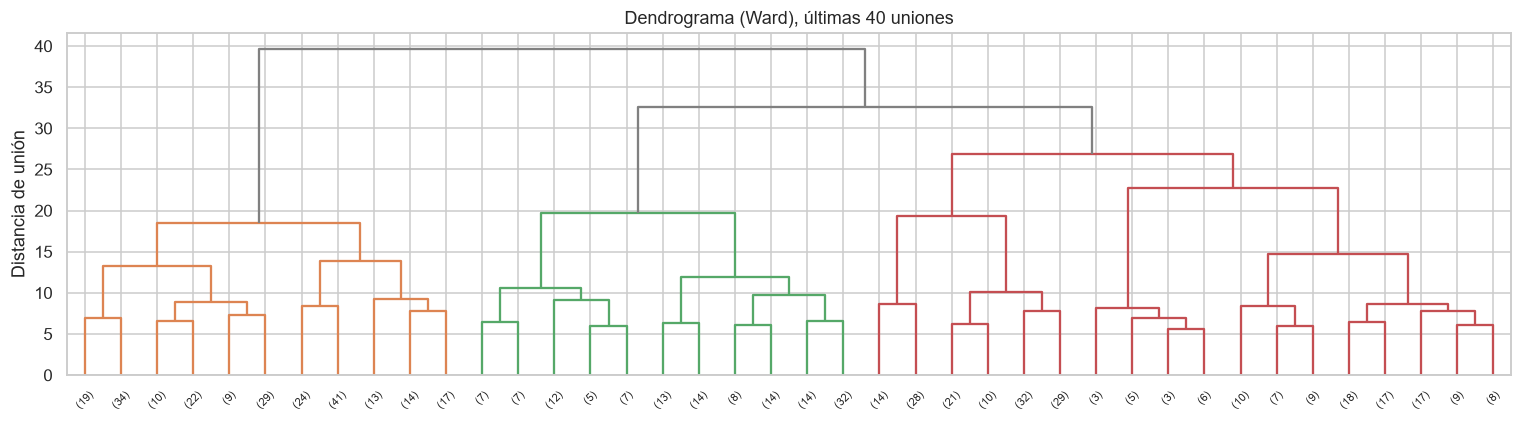

,enlace,k,silhouette,tamaños,ARI vs K-Means k=5
0,ward,3,0.156,"[246, 232, 133]",NaN
1,ward,4,0.145,"[232, 134, 133, 112]",NaN
2,ward,5,0.155,"[232, 134, 133, 95, 17]",0.437
3,ward,6,0.149,"[232, 134, 95, 95, 38, 17]",NaN
4,ward,7,0.144,"[232, 95, 95, 92, 42, 38, 17]",NaN
5,average,3,0.315,"[585, 17, 9]",NaN
6,average,4,0.225,"[585, 17, 8, 1]",NaN
7,average,5,0.187,"[542, 43, 17, 8, 1]",0.085
8,average,6,0.184,"[542, 43, 11, 8, 6, 1]",NaN
9,average,7,0.181,"[542, 43, 10, 8, 6, 1, 1]",NaN


In [26]:
from scipy.cluster.hierarchy import dendrogram, linkage

fig, ax = plt.subplots(figsize=(14, 4))
dendrogram(linkage(Z, "ward"), truncate_mode="lastp", p=40, ax=ax, color_threshold=None,
           above_threshold_color="gray", leaf_font_size=7)
ax.set(title="Dendrograma (Ward), últimas 40 uniones", ylabel="Distancia de unión")
plt.tight_layout(); plt.show()

rows = []
km_labels = KMeans(K_SEG, n_init=20, random_state=RANDOM_STATE).fit_predict(Z)
for link in ["ward", "average", "complete"]:
    for k in range(3, 8):
        lab = AgglomerativeClustering(k, linkage=link).fit_predict(Z)
        rows.append({"enlace": link, "k": k, "silhouette": silhouette_score(Z, lab),
                     "tamaños": sorted(np.bincount(lab).tolist(), reverse=True),
                     f"ARI vs K-Means k={K_SEG}": adjusted_rand_score(km_labels, lab) if k == K_SEG else np.nan})
agg_scores = pd.DataFrame(rows)
agg_scores.round(3)

**Lectura:**
- **Ward** produce grupos de tamaño razonable, pero con silhouette menor que K-Means (0.155 vs 0.187 en k = 5) y separa un grupo de 17 vendedores extremos. Su acuerdo con K-Means (ARI ≈ 0.44) es moderado: coinciden en la estructura gruesa y difieren en los bordes, lo esperable si no hay fronteras naturales marcadas.
- **Average** tiene el silhouette más alto en k = 3, pero es engañoso: deja un grupo gigante (585 de 611) y unos pocos vendedores sueltos. Es el efecto de "encadenamiento" típico de este enlace, y no sirve como segmentación.
- **Complete** queda en medio y con peor silhouette.
- **Conclusión:** el clustering jerárquico confirma que no hay grupos naturales muy separados y que la partición de K-Means es la más equilibrada. Se elige K-Means porque además asigna vendedores nuevos con `predict`, algo que el aglomerativo de scikit-learn no permite y que el despliegue necesita.

### 8.4 DBSCAN: ¿hay grupos por densidad o vendedores atípicos?

`min_samples = 2 × dimensiones = 16` (regla práctica). `eps` se elige con la gráfica de distancia al 16.º vecino: el "codo" de la curva separa puntos de zonas densas de puntos aislados.

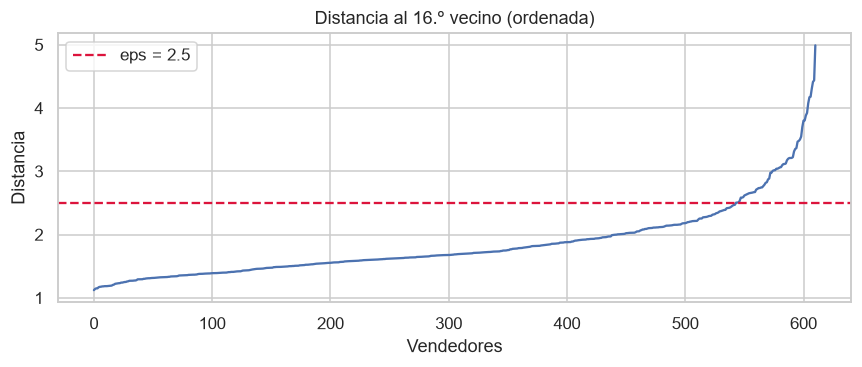

,eps,clusters,ruido (atípicos)
0,1.5,1,245
1,2.0,1,65
2,2.5,1,18
3,3.0,1,6


,seller_log_orders,seller_late_rate,seller_bad_rate,seller_handling_mean,seller_log_price_mean,seller_freight_ratio_mean,seller_log_distance_mean,seller_same_state_share
atípicos (DBSCAN),3.783,0.137,0.258,10.278,5.02,0.201,6.046,0.346
resto,3.932,0.057,0.122,2.252,4.46,0.262,5.895,0.364


In [27]:
MIN_SAMPLES = 2 * Z.shape[1]
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)[0][:, -1])
EPS = 2.5

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(kdist)
ax.axhline(EPS, ls="--", color="crimson", label=f"eps = {EPS}")
ax.set(title=f"Distancia al {MIN_SAMPLES}.º vecino (ordenada)", xlabel="Vendedores", ylabel="Distancia")
ax.legend(); plt.tight_layout(); plt.show()

rows = []
for eps in [1.5, 2.0, 2.5, 3.0]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Z)
    rows.append({"eps": eps, "clusters": len(set(lab) - {-1}), "ruido (atípicos)": int((lab == -1).sum())})
display(pd.DataFrame(rows))

db_labels = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Z)
outliers = active[db_labels == -1]
pd.DataFrame({"atípicos (DBSCAN)": outliers[SELLER].median(), "resto": active[db_labels != -1][SELLER].median()}).T.round(3)

**Lectura:**
- Para cualquier `eps` razonable, DBSCAN encuentra **un solo grupo denso** y un conjunto de puntos de ruido. Esto confirma lo que sugerían el silhouette y el enlace *average*: los perfiles de vendedores son un continuo, no islas separadas por zonas vacías. DBSCAN no sirve aquí para segmentar.
- En cambio, sirve para **detectar vendedores atípicos**: con `eps = 2.5` aísla 18 vendedores con alistamiento de ~10 días (vs ~2), 14 % de retrasos y 26 % de reseñas malas (el doble que el resto). Es una lista accionable: vendedores a revisar de inmediato.

### 8.5 PCA: visualización y estructura de los perfiles

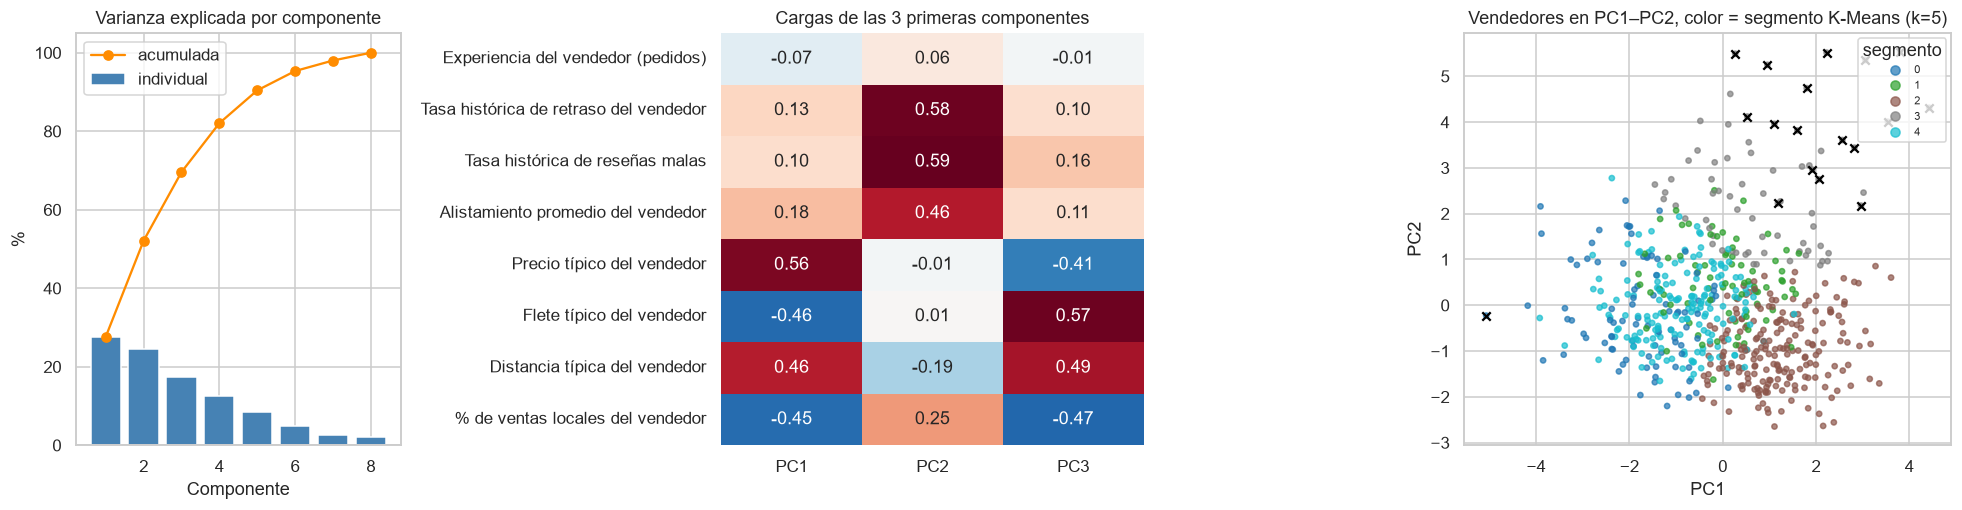

PC1+PC2 explican 52% de la varianza; se necesitan 5 componentes para el 90 %.


In [28]:
pca = PCA().fit(Z)
P = pca.transform(Z)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1.3, 1.5]})
axes[0].bar(range(1, 9), pca.explained_variance_ratio_ * 100, color="steelblue", label="individual")
axes[0].plot(range(1, 9), pca.explained_variance_ratio_.cumsum() * 100, marker="o", color="darkorange", label="acumulada")
axes[0].set(title="Varianza explicada por componente", xlabel="Componente", ylabel="%"); axes[0].legend()

loadings = pd.DataFrame(pca.components_[:3].T, index=[ml.LABELS[s] for s in SELLER], columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=axes[1], cbar=False)
axes[1].set(title="Cargas de las 3 primeras componentes")

sc = axes[2].scatter(P[:, 0], P[:, 1], c=km_labels, cmap="tab10", s=12, alpha=.7)
axes[2].scatter(P[db_labels == -1, 0], P[db_labels == -1, 1], marker="x", color="black", s=30, label="atípico (DBSCAN)")
axes[2].set(title=f"Vendedores en PC1–PC2, color = segmento K-Means (k={K_SEG})", xlabel="PC1", ylabel="PC2")
axes[2].legend(*sc.legend_elements(), title="segmento", fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()
print(f"PC1+PC2 explican {pca.explained_variance_ratio_[:2].sum():.0%} de la varianza; "
      f"se necesitan {np.searchsorted(pca.explained_variance_ratio_.cumsum(), .9) + 1} componentes para el 90 %.")

**Lectura:**
- Las dos primeras componentes explican ~52 % de la varianza y tienen una lectura de negocio clara:
  - **PC1, "tipo de negocio":** precio alto y venta a distancia (+) frente a flete caro y venta local (−).
  - **PC2, "calidad operativa":** tasa de retraso, reseñas malas y alistamiento lento cargan juntos (~0.5–0.6). Los vendedores problemáticos se ven arriba en la gráfica, junto con los atípicos de DBSCAN (×).
- Se necesitan 5 componentes para el 90 %: las 8 variables no son redundantes, así que la segmentación se hace sobre las 8 variables estandarizadas y PCA se usa para **visualizar e interpretar**, no para reducir.
- En el plano PC1–PC2 los segmentos se solapan en los bordes, coherente con el silhouette bajo; se separan sobre todo a lo largo de PC1 (tipo de negocio) y PC2 (calidad).

### 8.6 Segmentación final e interpretación de negocio

Se entrena el `Pipeline` final (recorte → escalado → K-Means) y se nombran los segmentos con reglas sobre sus centroides (así los nombres no dependen del número que K-Means le asigna a cada grupo).

Número de K-Means → segmento (colores de la gráfica PCA): {np.int32(0): 'Baratos con flete alto', np.int32(1): 'Alto volumen', np.int32(2): 'Nacionales (envían lejos)', np.int32(3): 'Lentos y con quejas', 4: 'Locales ágiles'}


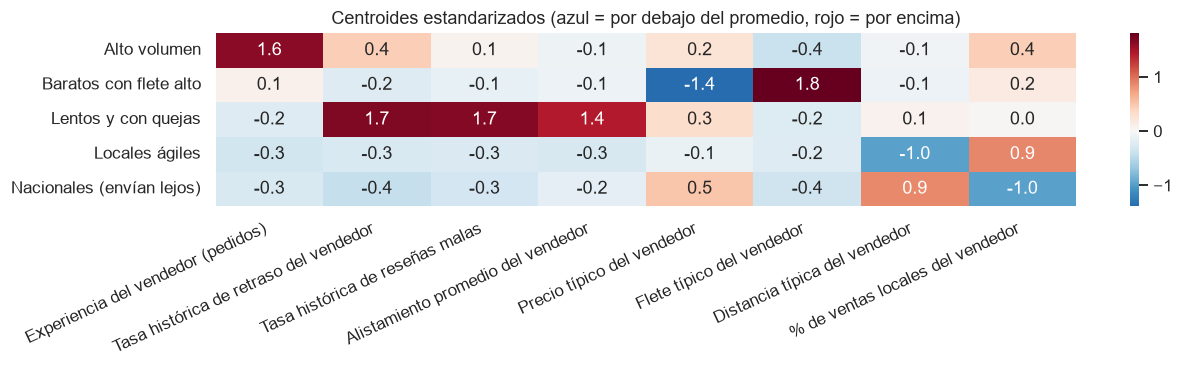

,vendedores,pedidos_mediana,tasa_retraso,tasa_resena_mala,alistamiento_dias,precio_tipico,flete_sobre_precio,distancia_km,ventas_locales
segmento,,,,,,,,,
Alto volumen,77,231.0,0.083,0.133,2.609,111.109,0.228,334.042,0.416
Baratos con flete alto,90,56.0,0.057,0.119,2.190,34.812,0.597,343.366,0.374
Lentos y con quejas,72,41.0,0.131,0.212,4.673,105.841,0.251,376.476,0.356
Locales ágiles,170,39.5,0.052,0.117,1.938,73.795,0.252,201.079,0.481
Nacionales (envían lejos),202,39.5,0.049,0.112,2.191,111.807,0.224,569.098,0.108


In [29]:
segmenter = Pipeline([("recortar", ml.Winsorizer(0.01, 0.99)), ("escalar", StandardScaler()),
                      ("kmeans", KMeans(K_SEG, n_init=20, random_state=RANDOM_STATE))]).fit(active[SELLER])
active["cluster"] = segmenter.predict(active[SELLER])
centers = active.groupby("cluster")[SELLER].median()


def name_segments(c):
    rules = [("Lentos y con quejas", "seller_late_rate", "max"),
             ("Alto volumen", "seller_log_orders", "max"),
             ("Baratos con flete alto", "seller_freight_ratio_mean", "max"),
             ("Nacionales (envían lejos)", "seller_same_state_share", "min")]
    names, left = {}, list(c.index)
    for name, col, how in rules:
        k = c.loc[left, col].idxmax() if how == "max" else c.loc[left, col].idxmin()
        names[k] = name
        left.remove(k)
    names.update({k: "Locales ágiles" for k in left})
    return names


SEG_NAMES = name_segments(centers)
active["segmento"] = active.cluster.map(SEG_NAMES)
print("Número de K-Means → segmento (colores de la gráfica PCA):", dict(sorted(SEG_NAMES.items())))

profile = active.groupby("segmento").agg(
    vendedores=("cluster", "size"),
    pedidos_mediana=("seller_known_orders", "median"),
    tasa_retraso=("seller_late_rate", "median"),
    tasa_resena_mala=("seller_bad_rate", "median"),
    alistamiento_dias=("seller_handling_mean", "median"),
    precio_tipico=("seller_log_price_mean", lambda s: np.expm1(s.median())),
    flete_sobre_precio=("seller_freight_ratio_mean", "median"),
    distancia_km=("seller_log_distance_mean", lambda s: np.expm1(s.median())),
    ventas_locales=("seller_same_state_share", "median"),
)
zc = pd.DataFrame(segmenter[:-1].transform(active[SELLER]), columns=[ml.LABELS[s] for s in SELLER]).groupby(
    active.segmento.values).mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(zc, cmap="RdBu_r", center=0, annot=True, fmt=".1f", ax=ax)
ax.set(title="Centroides estandarizados (azul = por debajo del promedio, rojo = por encima)", ylabel="")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
profile.round(3)

**Interpretación y uso de negocio:**

| Segmento | Qué lo distingue | Acción sugerida para operaciones |
|---|---|---|
| **Lentos y con quejas** (~12 %) | Retraso ~13 % y reseñas malas ~21 % (el doble que el resto), alistamiento de ~4.7 días | Acompañamiento prioritario: acordar tiempos de alistamiento, auditar su promesa de entrega |
| **Alto volumen** (~13 %) | Mediana de 231 pedidos, retraso algo mayor que el promedio (~8 %) | Cuentas clave: un punto de contacto dedicado, porque pequeños problemas afectan a muchos clientes |
| **Baratos con flete alto** (~15 %) | Precio típico ~R$ 35 y flete ≈ 60 % del valor | Revisar tarifas o incentivar el envío consolidado; el flete caro afecta la conversión |
| **Nacionales (envían lejos)** (~33 %) | Solo ~11 % de ventas locales, distancia típica ~570 km, buen cumplimiento | Bajo riesgo; vigilar en temporadas pico, cuando la distancia pesa más |
| **Locales ágiles** (~28 %) | ~48 % de ventas en su estado, alistamiento más rápido (~1.9 días) | Referentes de buenas prácticas |

La lectura es consistente con PCA: un eje de tipo de negocio (local/barato ↔ nacional/caro) y un eje de calidad operativa que aísla a los "Lentos y con quejas".

### 8.7 Del no supervisado al supervisado: segmento de cada pedido

Cada pedido recibe el segmento de su vendedor **según su perfil en el momento del despacho** (4.1), usando los centroides aprendidos arriba. Vendedores con menos de 20 pedidos entregados quedan como "Nuevo / poco historial". Así el segmento es una variable más, disponible en producción y sin fuga.

> Matiz honesto: los centroides se aprendieron con la foto al 1-may-2018, que resume pedidos del entrenamiento. Es información agregada de ~600 vendedores (no la etiqueta de un pedido), y la evaluación final en prueba (may–ago 2018) queda totalmente libre de ella.

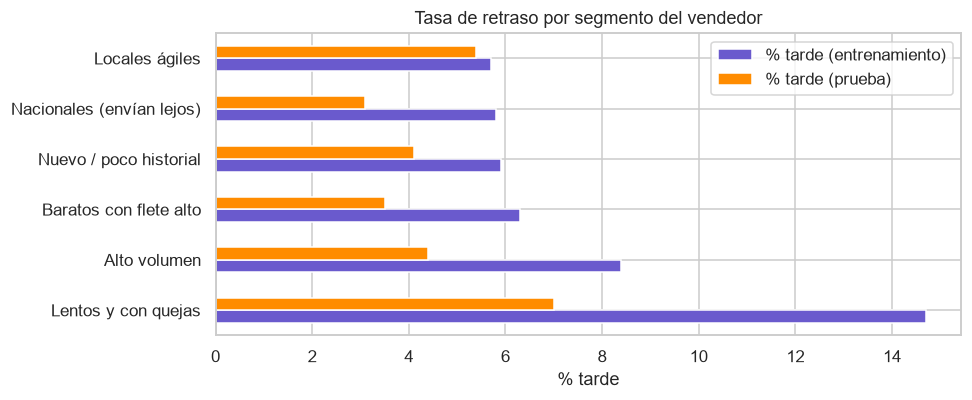

,% pedidos (entrenamiento),% tarde (entrenamiento),% tarde (prueba)
seller_segment,,,
Lentos y con quejas,2.2,14.7,7.0
Alto volumen,20.5,8.4,4.4
Baratos con flete alto,10.8,6.3,3.5
Nuevo / poco historial,34.6,5.9,4.1
Nacionales (envían lejos),16.2,5.8,3.1
Locales ágiles,15.7,5.7,5.4


In [30]:
df["seller_segment"] = ml.assign_segment(df, segmenter, SEG_NAMES)
train, test = split(df)

seg_rates = pd.DataFrame({
    "% pedidos (entrenamiento)": train.seller_segment.value_counts(normalize=True),
    "% tarde (entrenamiento)": train.groupby("seller_segment").late.mean(),
    "% tarde (prueba)": test.groupby("seller_segment").late.mean(),
}).mul(100).round(1).sort_values("% tarde (entrenamiento)", ascending=False)
seg_rates[["% tarde (entrenamiento)", "% tarde (prueba)"]].plot(kind="barh", figsize=(9, 3.8), color=["slateblue", "darkorange"])
plt.title("Tasa de retraso por segmento del vendedor"); plt.xlabel("% tarde"); plt.ylabel("")
plt.tight_layout(); plt.show()
seg_rates

**Lectura:**
- El segmento **sí ordena el riesgo** y ese orden se mantiene en el futuro: "Lentos y con quejas" es el segmento con más retrasos tanto en entrenamiento (~15 %) como en prueba (~7 %), cerca del doble que los mejores segmentos. Que la relación se sostenga en datos no vistos indica que la segmentación captura algo real y no ruido.
- Pero ese segmento concentra solo ~2 % de los pedidos, y un tercio de los pedidos viene de vendedores con poco historial. Por eso es de esperar que el segmento aporte poco **adicional** a un modelo que ya ve cómo se comportó el vendedor en el propio despacho (alistamiento, despacho tarde). Eso se mide en 9.3.
- Las tasas de prueba son más bajas en todos los segmentos porque may–ago 2018 fue un periodo con menos retrasos (4.4 % vs 6.6 %); se ve otra vez la deriva temporal.

## 9. Fase supervisada: entrenamiento y selección del modelo (3.4, 3.5)

### 9.1 Metodología de validación

- **Validación cruzada temporal** (`TimeSeriesSplit`, 4 folds) sobre el periodo de entrenamiento: cada fold entrena con el pasado y valida con el bloque siguiente. Entre ambos se deja una **brecha de 2 000 pedidos** (~3 semanas), que imita el tiempo que tarda en conocerse si un pedido llegó tarde.
- **Métrica de selección: PR-AUC** (precisión promedio). Con ~7 % de positivos, la exactitud no sirve (predecir siempre "a tiempo" daría 93 %), y la ROC-AUC se ve optimista porque premia ordenar bien la gran masa de negativos. La PR-AUC mide directamente qué tan limpia es la lista de pedidos que el modelo marca. Se reporta ROC-AUC como complemento. Justificación ampliada en la sección 11.
- Línea base: un clasificador trivial que predice la tasa de retraso (`DummyClassifier`): su PR-AUC es igual a la prevalencia.

In [31]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.kernel_approximation import Nystroem
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

y_train, y_test = train.late.values, test.late.values
tss = TimeSeriesSplit(n_splits=4, gap=2000)
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc"}

pd.DataFrame([{
    "fold": i + 1,
    "entrena hasta": train.order_purchase_timestamp.iloc[a[-1]].date(),
    "valida desde": train.order_purchase_timestamp.iloc[b[0]].date(),
    "valida hasta": train.order_purchase_timestamp.iloc[b[-1]].date(),
    "n entrenamiento": len(a), "n validación": len(b), "% tarde validación": round(y_train[b].mean() * 100, 1),
} for i, (a, b) in enumerate(tss.split(train))]).set_index("fold")

,entrena hasta,valida desde,valida hasta,n entrenamiento,n validación,% tarde validación
fold,,,,,,
1,2017-05-19,2017-06-06,2017-09-07,9406,11406,3.0
2,2017-08-22,2017-09-07,2017-11-22,20812,11406,5.4
3,2017-11-12,2017-11-22,2018-01-11,32218,11406,9.9
4,2018-01-02,2018-01-11,2018-02-28,43624,11406,10.9


### 9.2 Comparación de modelos y búsqueda de hiperparámetros

Para cada modelo visto en el curso se buscan hiperparámetros con validación cruzada temporal (búsqueda en malla cuando la malla es pequeña, aleatoria cuando es grande). Todos los modelos reciben las mismas variables base (pedido + despacho) y el mismo preprocesamiento.

| Modelo | Hiperparámetros explorados | Por qué estos rangos |
|---|---|---|
| kNN | vecinos 50–1000, peso uniforme/distancia | Con 7 % de positivos se necesitan muchos vecinos para estimar una probabilidad estable |
| Árbol de decisión | profundidad 4–12, hojas mín. 50–500, `class_weight` | Controlar el sobreajuste de un único árbol |
| Random Forest | profundidad, hojas mín., `max_features`, `class_weight` | Variedad entre árboles vs. sesgo |
| Gradient Boosting | tasa de aprendizaje, iteraciones, hojas, hojas mín., regularización L2 | Se usa `HistGradientBoostingClassifier`: el mismo algoritmo de boosting visto en clase, con histogramas para entrenar rápido 57 mil filas |
| SVM | `C` y `gamma` del kernel RBF | SVC exacto escala O(n²)–O(n³) con 57 mil filas; se usa la aproximación de Nyström del kernel RBF (600 componentes) + SVM lineal, que conserva el mismo modelo con costo lineal |

In [32]:
def model_pipeline(model, num=BASE_NUM, cat=CAT):
    return Pipeline([("prep", make_preprocessor(num, cat)), ("model", model)])


searches = {
    "Línea base (Dummy)": (DummyClassifier(strategy="prior"), {}),
    "kNN": (KNeighborsClassifier(), {"model__n_neighbors": [50, 150, 300, 600, 1000],
                                     "model__weights": ["uniform", "distance"]}),
    "Árbol de decisión": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                          {"model__max_depth": [4, 6, 8, 12], "model__min_samples_leaf": [50, 200, 500],
                           "model__class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
                      {"model__max_depth": [8, 14, None], "model__min_samples_leaf": [3, 10, 30, 100],
                       "model__max_features": ["sqrt", 0.3, 0.5], "model__class_weight": [None, "balanced_subsample"]}),
    "Gradient Boosting": (HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE),
                          {"model__learning_rate": [0.01, 0.03, 0.06, 0.1], "model__max_iter": [150, 300, 600],
                           "model__max_leaf_nodes": [7, 15, 31], "model__min_samples_leaf": [100, 300, 1000],
                           "model__l2_regularization": [1.0, 5.0, 20.0]}),
    "SVM (RBF, Nyström)": (Pipeline([("rbf", Nystroem(n_components=600, random_state=RANDOM_STATE)),
                                     ("svm", LinearSVC(class_weight="balanced", max_iter=5000))]),
                           {"model__rbf__gamma": [0.001, 0.003, 0.01, 0.03], "model__svm__C": [0.03, 0.1, 0.3, 1.0]}),
}
N_ITER = {"Random Forest": 12, "Gradient Boosting": 25}

rows, best_params, search_tables = [], {}, {}
for name, (model, grid) in searches.items():
    t = time.time()
    kw = dict(scoring=SCORING, refit=False, cv=tss, n_jobs=-1, return_train_score=True)
    search = (RandomizedSearchCV(model_pipeline(model), grid, n_iter=N_ITER[name], random_state=RANDOM_STATE, **kw)
              if name in N_ITER else GridSearchCV(model_pipeline(model), grid, **kw))
    search.fit(train, y_train)
    r = pd.DataFrame(search.cv_results_)
    i = r.mean_test_pr_auc.idxmax()
    best_params[name], search_tables[name] = r.params[i], r
    rows.append({"modelo": name, "PR-AUC val": r.mean_test_pr_auc[i], "± (folds)": r.std_test_pr_auc[i],
                 "ROC-AUC val": r.mean_test_roc_auc[i], "PR-AUC train": r.mean_train_pr_auc[i],
                 "combinaciones": len(r), "minutos": (time.time() - t) / 60,
                 "mejores hiperparámetros": {k.replace("model__", ""): v for k, v in r.params[i].items()}})
cv_results = pd.DataFrame(rows).set_index("modelo").sort_values("PR-AUC val", ascending=False)
cv_results.round(3)

,PR-AUC val,± (folds),ROC-AUC val,PR-AUC train,combinaciones,minutos,mejores hiperparámetros
modelo,,,,,,,
"SVM (RBF, Nyström)",0.315,0.061,0.767,0.288,16,2.235,"{'rbf__gamma': 0.003, 'svm__C': 0.1}"
Gradient Boosting,0.306,0.056,0.748,0.356,25,1.232,"{'min_samples_leaf': 100, 'max_leaf_nodes': 7,..."
Random Forest,0.297,0.049,0.744,0.552,12,2.304,"{'min_samples_leaf': 30, 'max_features': 0.3, ..."
kNN,0.271,0.041,0.725,1.000,10,1.490,"{'n_neighbors': 1000, 'weights': 'distance'}"
Árbol de decisión,0.243,0.050,0.688,0.314,24,0.195,"{'class_weight': 'balanced', 'max_depth': 8, '..."
Línea base (Dummy),0.073,0.033,0.500,0.043,1,0.105,{}


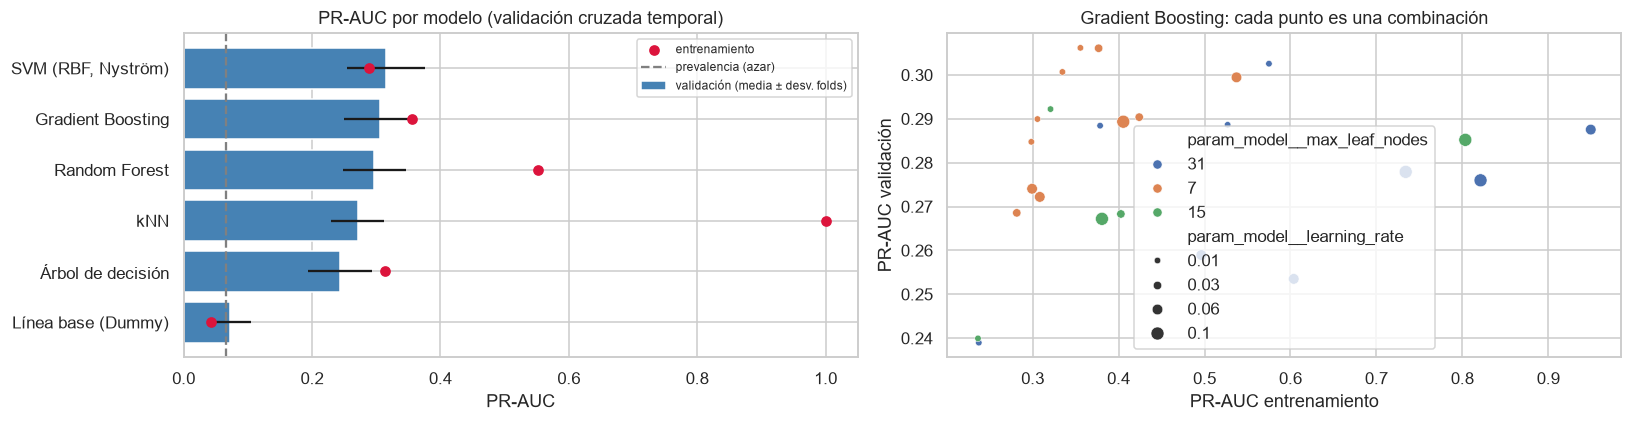

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
order = cv_results.index[::-1]
axes[0].barh(order, cv_results.loc[order, "PR-AUC val"], xerr=cv_results.loc[order, "± (folds)"], color="steelblue",
             label="validación (media ± desv. folds)")
axes[0].scatter(cv_results.loc[order, "PR-AUC train"], order, color="crimson", zorder=3, label="entrenamiento")
axes[0].axvline(y_train.mean(), ls="--", color="gray", label="prevalencia (azar)")
axes[0].set(title="PR-AUC por modelo (validación cruzada temporal)", xlabel="PR-AUC"); axes[0].legend(fontsize=8)

gb = search_tables["Gradient Boosting"]
sns.scatterplot(x=gb.mean_train_pr_auc, y=gb.mean_test_pr_auc, hue=gb.param_model__max_leaf_nodes.astype(str),
                size=gb.param_model__learning_rate.astype(float), ax=axes[1])
axes[1].set(title="Gradient Boosting: cada punto es una combinación", xlabel="PR-AUC entrenamiento",
            ylabel="PR-AUC validación")
plt.tight_layout(); plt.show()

**Lectura:**
- Todos los modelos superan con amplitud a la línea base (PR-AUC ≈ prevalencia ≈ 0.07): hay señal real.
- **kNN sobreajusta**: con peso por distancia memoriza el entrenamiento (PR-AUC train = 1.0) y queda entre los peores en validación. El **árbol de decisión** queda por debajo de los ensambles, como se espera de un único árbol.
- **Random Forest** tiene la mayor brecha entre entrenamiento y validación de los ensambles (0.55 vs 0.30); Gradient Boosting, con árboles pequeños y regularización, la mantiene baja (0.36 vs 0.31).
- Los tres mejores (**SVM, Gradient Boosting, Random Forest**) quedan muy cerca. La diferencia entre el primero y el segundo es mucho menor que la variación entre folds (±0.06), que viene de que cada fold tiene distinta tasa de retraso (3 % a 11 %).
- En el SVM la PR-AUC de entrenamiento es *menor* que la de validación. No es un error: la PR-AUC depende de la prevalencia, y los folds de validación (más recientes) tienen más retrasos que el promedio del entrenamiento.
- **Rangos de búsqueda.** En una primera versión, el óptimo de Gradient Boosting, Random Forest y kNN quedó en el borde de la malla, así que se ampliaron los rangos. Con los rangos ampliados, Gradient Boosting pasó de 0.304 a 0.306 de PR-AUC: la superficie de desempeño es casi plana. Los óptimos que siguen en el borde (tasa de aprendizaje baja con más iteraciones; árboles de 7 hojas; kNN con 1000 vecinos) apuntan en la dirección de modelos más suaves y regularizados, y la ganancia de seguir ampliando sería del orden de milésimas.

Como la media no separa a los candidatos, se comparan **fold por fold** (misma partición para todos).

In [34]:
top = ["SVM (RBF, Nyström)", "Gradient Boosting", "Random Forest"]
per_fold = pd.DataFrame({
    n: [search_tables[n].loc[search_tables[n].mean_test_pr_auc.idxmax(), f"split{k}_test_pr_auc"] for k in range(4)]
    for n in top}, index=[f"fold {k + 1}" for k in range(4)])
per_fold["prevalencia"] = [y_train[b].mean() for _, b in tss.split(train)]
per_fold["SVM − GB"] = per_fold["SVM (RBF, Nyström)"] - per_fold["Gradient Boosting"]
edge = {n: [f"{p.replace('model__', '')}={v}" for p, v in best_params[n].items()
            if v in (searches[n][1][p][0], searches[n][1][p][-1]) and len(searches[n][1][p]) > 2]
        for n in searches if searches[n][1]}
print("Hiperparámetros óptimos en el borde de su rango:", {n: e for n, e in edge.items() if e} or "ninguno")
print(f"Diferencia media SVM − GB: {per_fold['SVM − GB'].mean():+.3f} "
      f"(desv. entre folds {per_fold['SVM − GB'].std():.3f}); SVM gana en {(per_fold['SVM − GB'] > 0).sum()} de 4 folds")
per_fold.round(3)

Hiperparámetros óptimos en el borde de su rango: {'kNN': ['n_neighbors=1000'], 'Árbol de decisión': ['min_samples_leaf=50'], 'Gradient Boosting': ['min_samples_leaf=100', 'max_leaf_nodes=7', 'max_iter=600', 'learning_rate=0.01']}
Diferencia media SVM − GB: +0.009 (desv. entre folds 0.012); SVM gana en 3 de 4 folds


,"SVM (RBF, Nyström)",Gradient Boosting,Random Forest,prevalencia,SVM − GB
fold 1,0.209,0.211,0.214,0.030,-0.002
fold 2,0.347,0.321,0.307,0.054,0.026
fold 3,0.353,0.347,0.332,0.099,0.006
fold 4,0.352,0.345,0.336,0.109,0.007


**Selección del modelo.** El desempeño no separa al SVM de Gradient Boosting: el SVM gana en 3 de 4 folds, por menos de 0.01 de PR-AUC en promedio, y Gradient Boosting gana el cuarto. Es una diferencia menor que su propia variación entre folds. Con un empate así, la decisión se toma por lo que exige el uso real (3.8):

| Criterio | SVM (RBF, Nyström) | Gradient Boosting |
|---|---|---|
| PR-AUC en validación temporal | ≈ igual | ≈ igual |
| ¿Entrega probabilidades? | No: solo un puntaje de margen; necesitaría una calibración adicional | Sí, y razonablemente calibradas sin pasos extra |
| Explicación para el usuario (SHAP) | Solo `KernelExplainer`: aproximado y lento (segundos por pedido) | `TreeExplainer`: exacto e instantáneo |
| Datos faltantes y categorías raras | Depende por completo del preprocesamiento | Robusto por construcción |
| Sobreajuste (train vs. validación) | Bajo | Bajo y controlado (árboles de 7 hojas, ≥ 100 pedidos por hoja, regularización L2) |

**Se elige Gradient Boosting** (`HistGradientBoostingClassifier` con los hiperparámetros de la búsqueda). La interfaz muestra una probabilidad y las razones de cada alerta; con el SVM las dos cosas serían aproximaciones añadidas encima de un modelo que no es mejor. El SVM queda documentado como alternativa equivalente.

In [35]:
BEST_NAME = "Gradient Boosting"


def tuned(name):
    """Modelo `name` con sus mejores hiperparámetros de la búsqueda."""
    return clone(searches[name][0]).set_params(**{k.replace("model__", ""): v for k, v in best_params[name].items()})


print("Modelo elegido:", BEST_NAME, "|", best_params[BEST_NAME])

Modelo elegido: Gradient Boosting | {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 7, 'model__max_iter': 600, 'model__learning_rate': 0.01, 'model__l2_regularization': 5.0}


### 9.3 ¿La fase no supervisada mejora la supervisada?

Se repite la validación cruzada del mejor modelo con distintos conjuntos de variables. Es el experimento que conecta los dos paradigmas: si el segmento del vendedor (K-Means) o su perfil aportan información que el pedido no tiene, la PR-AUC debe subir de forma consistente en los folds.

Además, para kNN (el modelo más sensible a la dimensión) se prueba **PCA como preprocesamiento**.

In [36]:
feature_sets = {
    "Base (pedido + despacho)": (BASE_NUM, CAT),
    "+ segmento K-Means": (BASE_NUM, CAT + ["seller_segment"]),
    "+ perfil del vendedor (8 var.)": (BASE_NUM + SELLER, CAT),
    "+ segmento + perfil": (BASE_NUM + SELLER, CAT + ["seller_segment"]),
    "+ congestión de la red": (BASE_NUM + NET, CAT),
    "Todas": (BASE_NUM + SELLER + NET, CAT + ["seller_segment"]),
}
rows = []
for name, (num, cat) in feature_sets.items():
    r = cross_validate(model_pipeline(tuned(BEST_NAME), num, cat), train, y_train, cv=tss, scoring=SCORING, n_jobs=4)
    rows.append({"variables": name, "PR-AUC val": r["test_pr_auc"].mean(), "±": r["test_pr_auc"].std(),
                 "ROC-AUC val": r["test_roc_auc"].mean(), **{f"fold {i + 1}": v for i, v in enumerate(r["test_pr_auc"])}})
fs_results = pd.DataFrame(rows).set_index("variables")
base_folds = fs_results.loc["Base (pedido + despacho)", [f"fold {i}" for i in range(1, 5)]].values
fs_results["folds que mejoran vs base"] = [
    int((fs_results.loc[n, [f"fold {i}" for i in range(1, 5)]].values > base_folds).sum()) for n in fs_results.index]
fs_results.round(3)

,PR-AUC val,±,ROC-AUC val,fold 1,fold 2,fold 3,fold 4,folds que mejoran vs base
variables,,,,,,,,
Base (pedido + despacho),0.306,0.056,0.748,0.211,0.321,0.347,0.345,0
+ segmento K-Means,0.306,0.055,0.747,0.213,0.321,0.347,0.342,1
+ perfil del vendedor (8 var.),0.303,0.053,0.745,0.213,0.316,0.348,0.336,2
+ segmento + perfil,0.304,0.053,0.745,0.214,0.317,0.348,0.337,2
+ congestión de la red,0.303,0.051,0.741,0.217,0.311,0.335,0.347,2
Todas,0.303,0.048,0.738,0.222,0.310,0.334,0.345,1


In [37]:
knn = tuned("kNN")
rows = []
for name, steps in {"kNN sin PCA": [], "kNN + PCA (95 % varianza)": [("pca", PCA(0.95, random_state=RANDOM_STATE))],
                    "kNN + PCA (15 componentes)": [("pca", PCA(15, random_state=RANDOM_STATE))]}.items():
    pipe = Pipeline([("prep", make_preprocessor(BASE_NUM))] + steps + [("model", clone(knn))])
    r = cross_validate(pipe, train, y_train, cv=tss, scoring=SCORING, n_jobs=4)
    rows.append({"variante": name, "PR-AUC val": r["test_pr_auc"].mean(), "±": r["test_pr_auc"].std(),
                 "ROC-AUC val": r["test_roc_auc"].mean()})
pd.DataFrame(rows).set_index("variante").round(3)

,PR-AUC val,±,ROC-AUC val
variante,,,
kNN sin PCA,0.271,0.041,0.725
kNN + PCA (95 % varianza),0.271,0.040,0.722
kNN + PCA (15 componentes),0.262,0.038,0.701


**Lectura y decisión:**
- **El segmento K-Means no mejora el modelo:** PR-AUC 0.306 con y sin él, y solo mejora 1 de 4 folds. El perfil completo del vendedor y la congestión de la red tampoco: todas las variantes quedan entre 0.303 y 0.306, dentro del ruido, y ninguna mejora de forma consistente (como mucho 2 de 4 folds).
- **¿Por qué?** El modelo ya ve lo que el vendedor hizo *en este pedido*: cuánto tardó en alistar y si despachó fuera de plazo (5.8). Eso resume su comportamiento mejor que su promedio histórico. Además, un tercio de los pedidos es de vendedores con poco historial, para quienes el segmento no existe.
- **PCA no ayuda a kNN:** conservar el 95 % de la varianza deja la PR-AUC igual (0.271) y reducir a 15 componentes la empeora. Las 76 columnas no tienen tanta redundancia como para que kNN gane al quitarla.
- **Decisión:** el modelo final usa solo las variables del pedido y del despacho. Es el conjunto más simple, igual de bueno y con menos dependencias en producción (no necesita mantener el historial de cada vendedor actualizado para predecir). La segmentación no se descarta: se usa como **herramienta de negocio** (8.6) y se muestra en la interfaz junto a cada predicción.

In [38]:
FINAL_SET = "Base (pedido + despacho)"
FINAL_NUM, FINAL_CAT = feature_sets[FINAL_SET]

### 9.4 Desbalance de clases y data augmentation

Solo ~7 % de los pedidos llega tarde. Se comparan cinco estrategias sobre el modelo elegido, **siempre dentro de los folds de entrenamiento** (`imblearn.Pipeline`: el remuestreo se aplica en `fit` y nunca a los datos de validación; aplicarlo antes del split sería fuga):

| Estrategia | Qué hace |
|---|---|
| Sin tratamiento | El modelo ve la proporción real |
| `class_weight="balanced"` | Cada retraso pesa ~13 veces más en la función de pérdida |
| Submuestreo aleatorio | Descarta pedidos a tiempo hasta 30 % de positivos |
| **SMOTENC** | Crea retrasos sintéticos interpolando entre vecinos; maneja las categóricas sin inventar valores intermedios |
| **CTGAN** | Red generativa adversarial para tablas: aprende la distribución conjunta de los retrasos y genera nuevos (hasta 30 %) |

Además de PR-AUC y ROC-AUC se reporta el **Brier score** (error cuadrático de la probabilidad): la interfaz muestra probabilidades, así que importa que sean realistas.

In [39]:
import torch
from ctgan import CTGAN
from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

RATIO = 0.3
torch.set_num_threads(8)


def ctgan_oversample(X, y, ratio=RATIO, epochs=50):
    """Entrena CTGAN solo con los retrasos del fold y agrega retrasos sintéticos hasta `ratio`."""
    torch.manual_seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)
    pos = X[y == 1]
    n_new = int(ratio * (y == 0).sum()) - len(pos)
    discrete = [c for c in X.columns if c in FINAL_CAT or X[c].nunique() <= 10]
    gan = CTGAN(epochs=epochs, batch_size=500, enable_gpu=False)
    gan.fit(pos, discrete_columns=discrete)
    syn = gan.sample(n_new)
    num = [c for c in X.columns if c not in FINAL_CAT]
    syn[num] = syn[num].astype(float).clip(pos[num].min(), pos[num].max(), axis=1)  # CTGAN genera valores imposibles
    return pd.concat([X, syn], ignore_index=True), np.concatenate([y, np.ones(n_new, dtype=int)])


impute = ColumnTransformer([("num", SimpleImputer(strategy="median"), FINAL_NUM),
                            ("cat", SimpleImputer(strategy="most_frequent"), FINAL_CAT)],
                           verbose_feature_names_out=False).set_output(transform="pandas")
strategies = {
    "Sin tratamiento": (None, {}),
    "class_weight='balanced'": (None, {"class_weight": "balanced"}),
    "Submuestreo aleatorio": (RandomUnderSampler(sampling_strategy=RATIO, random_state=RANDOM_STATE), {}),
    "SMOTENC": (SMOTENC(categorical_features=FINAL_CAT, sampling_strategy=RATIO, random_state=RANDOM_STATE), {}),
    "CTGAN": (FunctionSampler(func=ctgan_oversample, validate=False), {}),
}
rows = []
for name, (sampler, extra) in strategies.items():
    t = time.time()
    steps = [("imputar", clone(impute))] + ([("balanceo", sampler)] if sampler is not None else [])
    steps += [("prep", make_preprocessor(FINAL_NUM, FINAL_CAT)), ("model", tuned(BEST_NAME).set_params(**extra))]
    r = cross_validate(ImbPipeline(steps), train[FINAL_NUM + FINAL_CAT], y_train, cv=tss,
                       scoring={**SCORING, "brier": "neg_brier_score"}, n_jobs=1 if name == "CTGAN" else 4)
    rows.append({"estrategia": name, "PR-AUC val": r["test_pr_auc"].mean(), "±": r["test_pr_auc"].std(),
                 "ROC-AUC val": r["test_roc_auc"].mean(), "Brier": -r["test_brier"].mean(),
                 "minutos": (time.time() - t) / 60})
imb_results = pd.DataFrame(rows).set_index("estrategia")
imb_results.round(4)

,PR-AUC val,±,ROC-AUC val,Brier,minutos
estrategia,,,,,
Sin tratamiento,0.3062,0.0558,0.7485,0.0603,0.1298
class_weight='balanced',0.3004,0.0553,0.7452,0.1767,0.0904
Submuestreo aleatorio,0.3011,0.0588,0.7455,0.0831,0.0258
SMOTENC,0.2890,0.0434,0.7352,0.0609,0.1083
CTGAN,0.2377,0.0520,0.6924,0.0627,0.8110


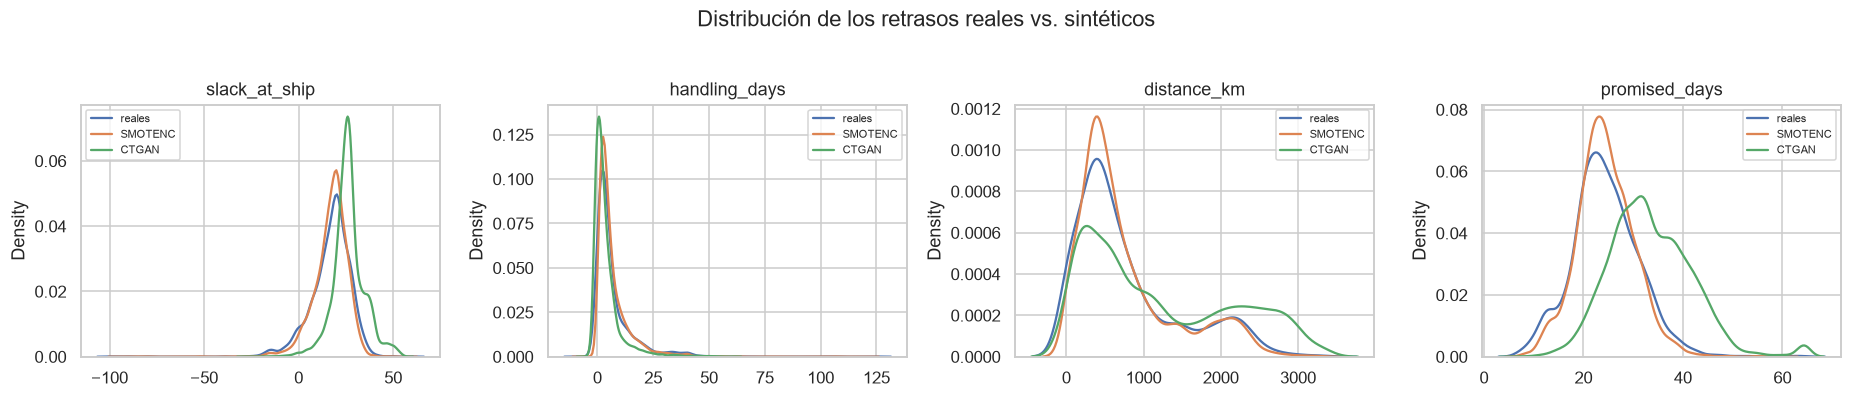

In [40]:
# ¿Qué tan parecidos son los retrasos sintéticos a los reales? (último fold de entrenamiento)
a, _ = list(tss.split(train))[-1]
Xa = impute.fit_transform(train.iloc[a])
X_ctgan, y_ctgan = ctgan_oversample(Xa, y_train[a])
X_smote, y_smote = SMOTENC(categorical_features=FINAL_CAT, sampling_strategy=RATIO,
                           random_state=RANDOM_STATE).fit_resample(Xa, y_train[a])
real = Xa[y_train[a] == 1]
syn_ctgan, syn_smote = X_ctgan.iloc[len(Xa):], X_smote.iloc[len(Xa):]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
for ax, col in zip(axes, ["slack_at_ship", "handling_days", "distance_km", "promised_days"]):
    for data, lab in [(real, "reales"), (syn_smote, "SMOTENC"), (syn_ctgan, "CTGAN")]:
        sns.kdeplot(data[col].astype(float), ax=ax, label=lab, common_norm=False)
    ax.set(title=col, xlabel=""); ax.legend(fontsize=7)
plt.suptitle("Distribución de los retrasos reales vs. sintéticos", y=1.03); plt.tight_layout(); plt.show()

**Lectura y decisión:**
- **Ninguna estrategia de balanceo mejora la PR-AUC:** sin tratamiento queda en 0.306; `class_weight` y submuestreo quedan apenas por debajo (0.300–0.301); SMOTENC baja a 0.289 y CTGAN a 0.238.
- **`class_weight` y el submuestreo distorsionan las probabilidades:** el Brier score empeora de 0.060 a 0.177 y 0.083, porque el modelo aprende que los retrasos son mucho más frecuentes de lo que son. Para una interfaz que muestra "X % de probabilidad de retraso", eso es un problema real.
- **Los datos sintéticos no se parecen lo suficiente a los reales.** SMOTENC reproduce bien las distribuciones (interpola entre retrasos reales), pero crea puntos en zonas donde también hay pedidos a tiempo, y eso confunde al modelo. CTGAN, entrenado con solo ~3 000 retrasos por fold, genera distribuciones desplazadas (por ejemplo, días prometidos más largos que los reales) e incluso valores imposibles (precios y pesos negativos, que hubo que recortar). Con tan pocos ejemplos, una red generativa no alcanza a aprender la distribución conjunta.
- **Decisión: no balancear.** Gradient Boosting ya maneja el desbalance al ordenar los pedidos por riesgo, y lo que importa en operación es ese orden (sección 11), no un umbral de 0.5. Que el data augmentation no sirva aquí también es un resultado: se probó dentro de los folds, se comparó con la misma métrica y se descartó con evidencia.

In [41]:
final_model = model_pipeline(tuned(BEST_NAME), FINAL_NUM, FINAL_CAT)
final_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the ou

### 9.5 Resumen de la selección

| Decisión | Alternativas comparadas | Evidencia | Elección |
|---|---|---|---|
| Algoritmo | Dummy, kNN, árbol, Random Forest, Gradient Boosting, SVM | PR-AUC en CV temporal, fold por fold | Gradient Boosting (empate con SVM; gana por probabilidades y SHAP exacto) |
| Hiperparámetros | 25 combinaciones aleatorias, rangos ampliados cuando el óptimo quedó en el borde | PR-AUC en CV temporal | `learning_rate=0.01`, 600 árboles de 7 hojas, ≥ 100 pedidos por hoja, L2 = 5 |
| Variables | Base, + segmento, + perfil del vendedor, + congestión, todas | Ninguna adición mejora de forma consistente | Base (pedido + despacho) |
| Desbalance | Nada, `class_weight`, submuestreo, SMOTENC, CTGAN | PR-AUC y Brier | Sin tratamiento |
| Preprocesamiento para kNN | Sin PCA, PCA 95 %, PCA 15 componentes | PR-AUC | Sin PCA |

## 10. Generalización (3.6)

Ahora sí se usa el conjunto de **prueba** (compras de may–ago 2018), una sola vez. El modelo se entrena con todo el periodo de entrenamiento y se compara su desempeño en entrenamiento, validación cruzada y prueba.

In [42]:
final_model.fit(train, y_train)
p_train = final_model.predict_proba(train)[:, 1]
p_test = final_model.predict_proba(test)[:, 1]
cv_row = fs_results.loc[FINAL_SET]
gen = pd.DataFrame({
    "PR-AUC": [average_precision_score(y_train, p_train), cv_row["PR-AUC val"], average_precision_score(y_test, p_test)],
    "ROC-AUC": [roc_auc_score(y_train, p_train), cv_row["ROC-AUC val"], roc_auc_score(y_test, p_test)],
    "prevalencia (PR-AUC del azar)": [y_train.mean(), y_train.mean(), y_test.mean()],
}, index=["Entrenamiento (en muestra)", "Validación cruzada temporal", "Prueba may–ago 2018"])
gen["PR-AUC / prevalencia (lift)"] = gen["PR-AUC"] / gen["prevalencia (PR-AUC del azar)"]
gen.round(3)

,PR-AUC,ROC-AUC,prevalencia (PR-AUC del azar),PR-AUC / prevalencia (lift)
Entrenamiento (en muestra),0.349,0.795,0.066,5.261
Validación cruzada temporal,0.306,0.748,0.066,4.618
Prueba may–ago 2018,0.394,0.824,0.044,8.961


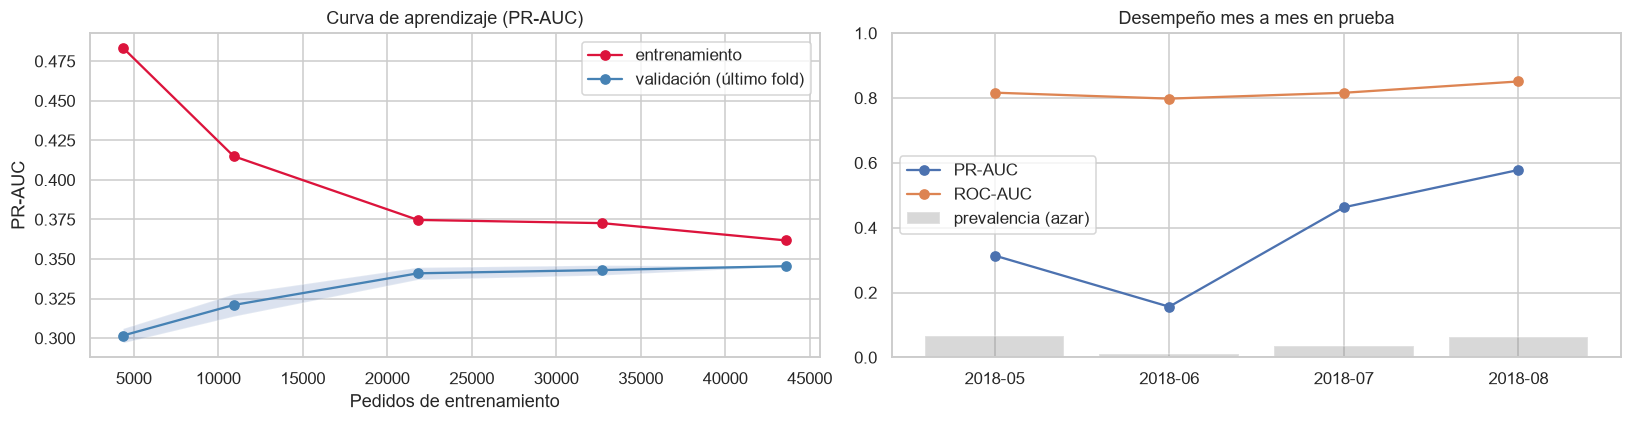

,PR-AUC,ROC-AUC,prevalencia,pedidos
purchase_month,,,,
2018-05,0.314,0.816,0.066,6749.0
2018-06,0.156,0.798,0.012,6096.0
2018-07,0.463,0.816,0.034,6156.0
2018-08,0.578,0.851,0.062,6351.0


In [43]:
# Curva de aprendizaje en el último fold temporal: submuestras aleatorias crecientes del entrenamiento
a, b = list(tss.split(train))[-1]
rng = np.random.default_rng(RANDOM_STATE)
lc = []
for frac in [0.1, 0.25, 0.5, 0.75, 1.0]:
    for rep in range(3 if frac < 1 else 1):
        idx = np.sort(rng.choice(a, int(frac * len(a)), replace=False))
        m = clone(final_model).fit(train.iloc[idx], y_train[idx])
        lc.append({"n": len(idx), "train": average_precision_score(y_train[idx], m.predict_proba(train.iloc[idx])[:, 1]),
                   "val": average_precision_score(y_train[b], m.predict_proba(train.iloc[b])[:, 1])})
lc = pd.DataFrame(lc).groupby("n").agg(["mean", "std"])
sizes = lc.index.values
tr_mean, va_mean, va_std = lc["train"]["mean"].values, lc["val"]["mean"].values, lc["val"]["std"].fillna(0).values

test_month = test.assign(p=p_test).groupby("purchase_month").apply(
    lambda g: pd.Series({"PR-AUC": average_precision_score(g.late, g.p), "ROC-AUC": roc_auc_score(g.late, g.p),
                         "prevalencia": g.late.mean(), "pedidos": len(g)}))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(sizes, tr_mean, marker="o", color="crimson", label="entrenamiento")
axes[0].plot(sizes, va_mean, marker="o", color="steelblue", label="validación (último fold)")
axes[0].fill_between(sizes, va_mean - va_std, va_mean + va_std, alpha=.2)
axes[0].set(title="Curva de aprendizaje (PR-AUC)", xlabel="Pedidos de entrenamiento", ylabel="PR-AUC"); axes[0].legend()
x = test_month.index.astype(str)
axes[1].plot(x, test_month["PR-AUC"], marker="o", label="PR-AUC")
axes[1].plot(x, test_month["ROC-AUC"], marker="o", label="ROC-AUC")
axes[1].bar(x, test_month["prevalencia"], alpha=.3, color="gray", label="prevalencia (azar)")
axes[1].set(title="Desempeño mes a mes en prueba", ylim=(0, 1)); axes[1].legend()
plt.tight_layout(); plt.show()
test_month.round(3)

### 10.1 Controles contra sobreajuste y fuga de información

Tres pruebas para demostrar que el desempeño no viene de una fuga:

1. **Etiquetas barajadas:** si se entrena con las etiquetas permutadas al azar, el modelo debe caer al nivel del azar. Si no cayera, habría información de la etiqueta escondida en las variables.
2. **Cómo se vería una fuga:** se agrega a propósito `delay_days` (conocida solo al entregar). El desempeño "perfecto" que resulta es la señal de alarma que nuestro modelo **no** tiene.
3. **Validación aleatoria vs. temporal:** con un `KFold` aleatorio el modelo "ve" el futuro dentro del entrenamiento; la diferencia frente a la validación temporal muestra cuánto se habría sobreestimado el desempeño.

In [44]:
from sklearn.model_selection import StratifiedKFold

shuffled = clone(final_model).fit(train, np.random.default_rng(RANDOM_STATE).permutation(y_train))
leaky = model_pipeline(tuned(BEST_NAME), FINAL_NUM + ["delay_days"], FINAL_CAT).fit(train, y_train)
cv_random = cross_validate(final_model, train, y_train, cv=StratifiedKFold(4, shuffle=True, random_state=RANDOM_STATE),
                           scoring=SCORING, n_jobs=4)
pd.DataFrame({
    "PR-AUC": [average_precision_score(y_test, p_test),
               average_precision_score(y_test, shuffled.predict_proba(test)[:, 1]),
               average_precision_score(y_test, leaky.predict_proba(test)[:, 1]),
               cv_row["PR-AUC val"], cv_random["test_pr_auc"].mean()],
    "ROC-AUC": [roc_auc_score(y_test, p_test), roc_auc_score(y_test, shuffled.predict_proba(test)[:, 1]),
                roc_auc_score(y_test, leaky.predict_proba(test)[:, 1]),
                cv_row["ROC-AUC val"], cv_random["test_roc_auc"].mean()],
}, index=["Modelo final (prueba)", "1. Etiquetas barajadas (prueba)", "2. Con fuga delay_days (prueba)",
          "3a. CV temporal (entrenamiento)", "3b. CV aleatoria (entrenamiento)"]).round(3)

,PR-AUC,ROC-AUC
Modelo final (prueba),0.394,0.824
1. Etiquetas barajadas (prueba),0.042,0.488
2. Con fuga delay_days (prueba),0.999,1.000
3a. CV temporal (entrenamiento),0.306,0.748
3b. CV aleatoria (entrenamiento),0.330,0.780


**Conclusión de generalización:**
- **No hay sobreajuste preocupante.** La PR-AUC en entrenamiento (0.35) está cerca de la de validación (0.31), y en la curva de aprendizaje las dos curvas se acercan a medida que crece el entrenamiento: la validación sube de 0.30 a 0.35 y se aplana a partir de ~20 000 pedidos. Más datos del mismo tipo ayudarían poco; lo que limita el desempeño es la información disponible al despachar, no la cantidad de ejemplos.
- **El modelo funciona en datos no vistos.** En la prueba (may–ago 2018) la PR-AUC es 0.39, **9 veces** la de un modelo al azar (0.044), y la ROC-AUC es 0.82. La ROC-AUC es estable mes a mes (0.80–0.85). La PR-AUC varía más (0.16 en junio, 0.58 en agosto) porque depende de cuántos retrasos hubo ese mes: en junio solo llegó tarde el 1.2 % de los pedidos, y aun así la lista es 13 veces mejor que el azar.
- **La prueba sale mejor que la validación cruzada** (0.39 vs 0.31 de PR-AUC). No es fuga: el modelo final se entrena con todo el periodo (más datos que cualquier fold) y la prueba no incluye los picos de retrasos de nov-2017 y feb–mar 2018, que son los meses más difíciles de los folds de validación.
- **No hay fuga de información:**
  1. Con etiquetas barajadas el modelo cae exactamente al azar (PR-AUC 0.042 vs prevalencia 0.044; ROC-AUC 0.49).
  2. Con una variable con fuga (`delay_days`) el modelo da 0.999: así se vería una fuga, y nuestro modelo está muy lejos de eso.
  3. Una validación cruzada aleatoria habría reportado 0.33 en vez de 0.31 de PR-AUC: habría sobreestimado el desempeño, como se esperaba por la deriva temporal. Por eso todo el proyecto usa validación temporal.

## 11. Métricas de desempeño (3.7)

**¿Por qué estas métricas?**
- **PR-AUC (selección del modelo):** resume, para todos los umbrales posibles, qué tan "limpia" es la lista de pedidos marcados (precisión) frente a cuántos retrasos atrapa (recall). Es la métrica adecuada cuando la clase de interés es minoritaria y lo que importa es la lista de alertas. Su referencia es la prevalencia (~4–7 %), no 0.5.
- **ROC-AUC (complemento):** probabilidad de que un pedido tardío reciba un puntaje mayor que uno a tiempo. Es fácil de comunicar, pero con desbalance se ve optimista.
- **Precisión y recall en el umbral de operación:** es lo que vive el usuario: *de cada 100 pedidos que la herramienta marca, cuántos llegan tarde* (precisión) y *qué porcentaje de todos los retrasos detectamos* (recall).
- **Brier / calibración:** la interfaz muestra una probabilidad; debe significar lo que dice.

**Cómo se convierten los puntajes en alertas.** El equipo de operaciones no puede revisar todos los despachos. Suponemos que puede revisar el **10 % diario** (≈27 de los ~270 despachos de un día típico de 2018). Se comparan tres políticas, todas definidas **sin mirar la prueba**:

- **A. Umbral fijo calculado en la validación cruzada:** el percentil 90 de las predicciones fuera de muestra de los folds.
- **B. Umbral fijo calculado con los despachos recientes:** el percentil 90 de los puntajes del modelo final sobre los pedidos despachados en mar–abr 2018. No necesita etiquetas (solo la distribución de puntajes), así que se puede calcular el mismo día del despliegue, sin fuga.
- **C. Top 10 % de cada día:** cada día se ordenan los despachos por riesgo y se marca el 10 % más alto. Respeta la capacidad del equipo por construcción.

In [45]:
oof = np.full(len(train), np.nan)
for a, b in tss.split(train):
    oof[b] = clone(final_model).fit(train.iloc[a], y_train[a]).predict_proba(train.iloc[b])[:, 1]

CAPACITY = 0.10
recent_ship = df[(df.order_purchase_timestamp >= TRAIN_END) & (df.order_delivered_carrier_date < TEST_START)]
p_recent = final_model.predict_proba(recent_ship)[:, 1]
THRESHOLD = float(np.quantile(p_recent, 1 - CAPACITY))  # riesgo alto (semáforo de la interfaz)
MEDIUM = float(np.quantile(p_recent, 0.75))              # riesgo medio
ship_day = test.order_delivered_carrier_date.dt.normalize().values
daily_rank = pd.Series(p_test).groupby(ship_day).rank(pct=True, ascending=False).values


def ops_metrics(flag):
    tp = (flag & (y_test == 1)).sum()
    return {"% marcados": flag.mean(), "precisión": tp / max(flag.sum(), 1), "recall": tp / y_test.sum(),
            "lift (precisión / prevalencia)": tp / max(flag.sum(), 1) / y_test.mean(),
            "% marcados con reseña 1–2": np.nanmean(test.bad_review.values[flag])}


policies = {
    "A. Umbral fijo de la CV": p_test >= np.nanquantile(oof, 1 - CAPACITY),
    "B. Umbral fijo con despachos recientes": p_test >= THRESHOLD,
    "C. Top 10 % de cada día": daily_rank <= CAPACITY,
}
ops = pd.DataFrame({k: ops_metrics(v) for k, v in policies.items()}).T
HEADLINE = ops.loc["C. Top 10 % de cada día"].to_dict()
print(f"Umbral A: {np.nanquantile(oof, 1 - CAPACITY):.3f} | umbral B (alto): {THRESHOLD:.3f} | medio: {MEDIUM:.3f}")
print(f"Reseñas 1–2 en todo el periodo de prueba: {np.nanmean(test.bad_review):.1%}")
display(ops.round(3))

by_month = pd.DataFrame({k: pd.Series(v).groupby(test.purchase_month.values).mean() for k, v in policies.items()})
by_month["prevalencia"] = pd.Series(y_test).groupby(test.purchase_month.values).mean()
by_month["mediana días prometidos"] = test.groupby("purchase_month").promised_days.median().values
print("% de despachos marcados por mes con cada política:")
display(by_month.round(3))

capacity_table = pd.DataFrame({f"{c:.0%} diario": ops_metrics(daily_rank <= c) for c in [0.05, 0.10, 0.20]}).T
print("Política C con distintas capacidades del equipo:")
capacity_table.round(3)

Umbral A: 0.083 | umbral B (alto): 0.135 | medio: 0.079
Reseñas 1–2 en todo el periodo de prueba: 10.0%


,% marcados,precisión,recall,lift (precisión / prevalencia),% marcados con reseña 1–2
A. Umbral fijo de la CV,0.271,0.115,0.712,2.625,0.126
B. Umbral fijo con despachos recientes,0.133,0.181,0.550,4.124,0.163
C. Top 10 % de cada día,0.098,0.218,0.485,4.958,0.184


% de despachos marcados por mes con cada política:


,A. Umbral fijo de la CV,B. Umbral fijo con despachos recientes,C. Top 10 % de cada día,prevalencia,mediana días prometidos
2018-05,0.211,0.093,0.111,0.066,21.465
2018-06,0.121,0.041,0.088,0.012,27.278
2018-07,0.337,0.168,0.105,0.034,19.333
2018-08,0.415,0.231,0.086,0.062,13.439


Política C con distintas capacidades del equipo:


,% marcados,precisión,recall,lift (precisión / prevalencia),% marcados con reseña 1–2
5% diario,0.048,0.313,0.341,7.111,0.241
10% diario,0.098,0.218,0.485,4.958,0.184
20% diario,0.198,0.137,0.619,3.123,0.147


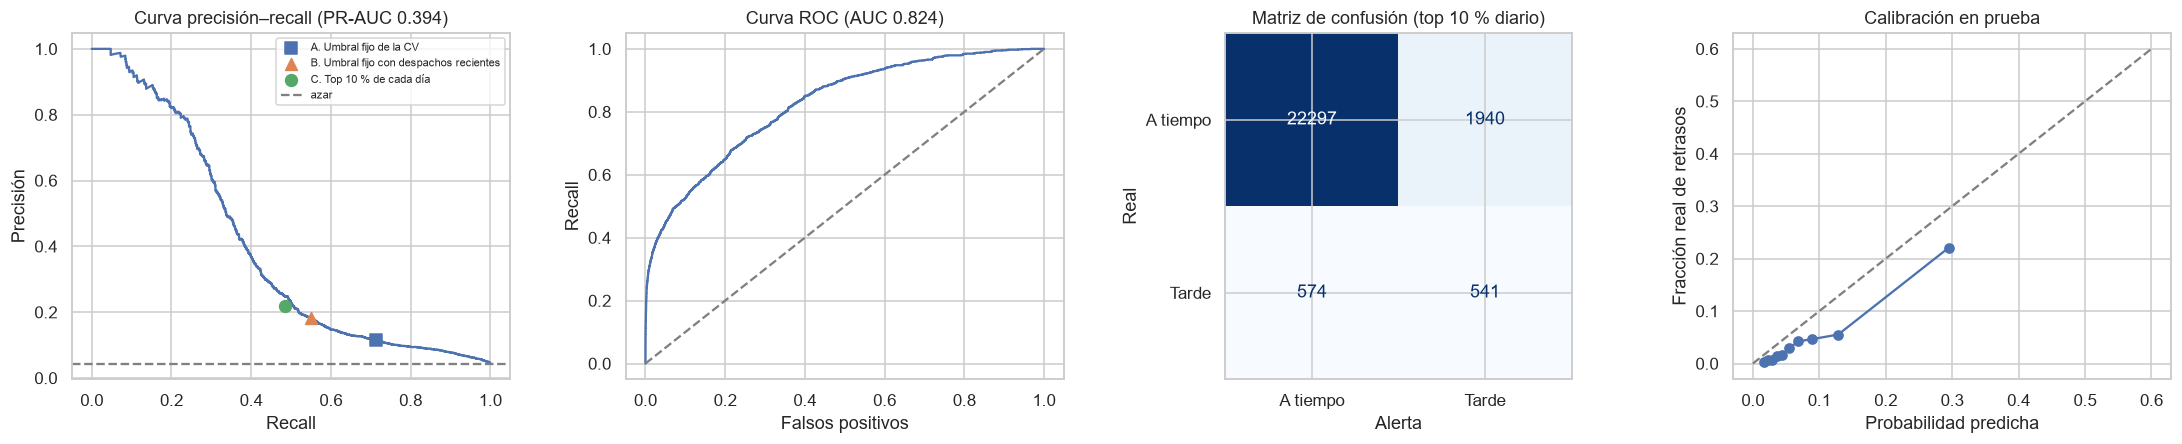

In [46]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

flag = policies["C. Top 10 % de cada día"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
prec, rec, _ = precision_recall_curve(y_test, p_test)
axes[0].plot(rec, prec)
for name, mk in zip(ops.index, ["s", "^", "o"]):
    axes[0].scatter(ops.loc[name, "recall"], ops.loc[name, "precisión"], marker=mk, s=60, zorder=3, label=name)
axes[0].axhline(y_test.mean(), ls="--", color="gray", label="azar")
axes[0].set(title=f"Curva precisión–recall (PR-AUC {average_precision_score(y_test, p_test):.3f})",
            xlabel="Recall", ylabel="Precisión"); axes[0].legend(fontsize=7)
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [0, 1], ls="--", color="gray")
axes[1].set(title=f"Curva ROC (AUC {roc_auc_score(y_test, p_test):.3f})", xlabel="Falsos positivos", ylabel="Recall")
ConfusionMatrixDisplay.from_predictions(y_test, flag.astype(int), display_labels=["A tiempo", "Tarde"],
                                        ax=axes[2], colorbar=False, cmap="Blues")
axes[2].set(title="Matriz de confusión (top 10 % diario)", xlabel="Alerta", ylabel="Real")
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
axes[3].plot(mean_pred, frac_pos, marker="o"); axes[3].plot([0, 0.6], [0, 0.6], ls="--", color="gray")
axes[3].set(title="Calibración en prueba", xlabel="Probabilidad predicha", ylabel="Fracción real de retrasos")
plt.tight_layout(); plt.show()

**Qué significan en el uso real:**
- **La política A no sirve:** el umbral calculado en la validación cruzada marca el 27 % de los despachos, casi el triple de lo que el equipo puede revisar. Los modelos de cada fold puntúan en otra escala que el modelo final entrenado con todo el periodo.
- **La política B se acerca más (13 %), pero no aguanta la deriva:** marca 4 % en junio y 23 % en agosto. En julio–agosto de 2018 Olist **acortó las fechas prometidas** (la mediana pasó de ~24 a 13 días; ver 14.1). Con menos margen, todos los puntajes suben aunque la tasa real de retrasos no cambie tanto.
- **La política C es la recomendada:** marcar cada día el 10 % de despachos de mayor riesgo. Por construcción respeta la capacidad del equipo todos los meses (9–11 %) y es la de mejor precisión.

**Traducción para el equipo de operaciones (política C, prueba may–ago 2018):**
- Revisando **~27 despachos de cada ~270 diarios**, **1 de cada 5 marcados llega tarde (precisión 22 %)**, frente a 1 de cada 23 si se eligieran al azar: **5 veces mejor**.
- Esa lista contiene **casi la mitad (48 %) de todos los retrasos** del periodo.
- Entre los pedidos marcados, el 18 % terminó con reseña de 1–2 estrellas, frente al 10 % del total: la lista apunta a los clientes que más se van a quejar.
- Si el equipo puede revisar solo el 5 %, la precisión sube a 31 % (7 veces el azar) y se detecta un tercio de los retrasos; con el 20 %, se detecta el 62 %.
- **Falsos positivos:** 4 de cada 5 pedidos marcados llegan a tiempo. Para la acción propuesta (revisar el rastreo, avisar al cliente) el costo de un falso positivo es bajo; el de un falso negativo es una reseña mala. Por eso se prioriza detectar retrasos aun con precisión moderada.

**Calibración:** en la prueba el modelo **sobreestima** la probabilidad en los pedidos de más riesgo (predice ~30 % y ocurre ~22 %). Es consecuencia de la deriva: el modelo aprendió en un periodo con 6.6 % de retrasos y la prueba tuvo 4.4 %. Por eso la interfaz presenta la probabilidad junto con un nivel de riesgo relativo, y la lista diaria usa el orden y no el valor absoluto.

## 12. Explicabilidad con SHAP

SHAP descompone cada predicción en la contribución de cada variable (en log-odds). Se usa para (a) entender qué aprendió el modelo globalmente, (b) verificar que lo que aprendió tiene sentido de negocio (otra defensa contra fugas) y (c) mostrarle al usuario de la interfaz **por qué** un pedido está en riesgo.

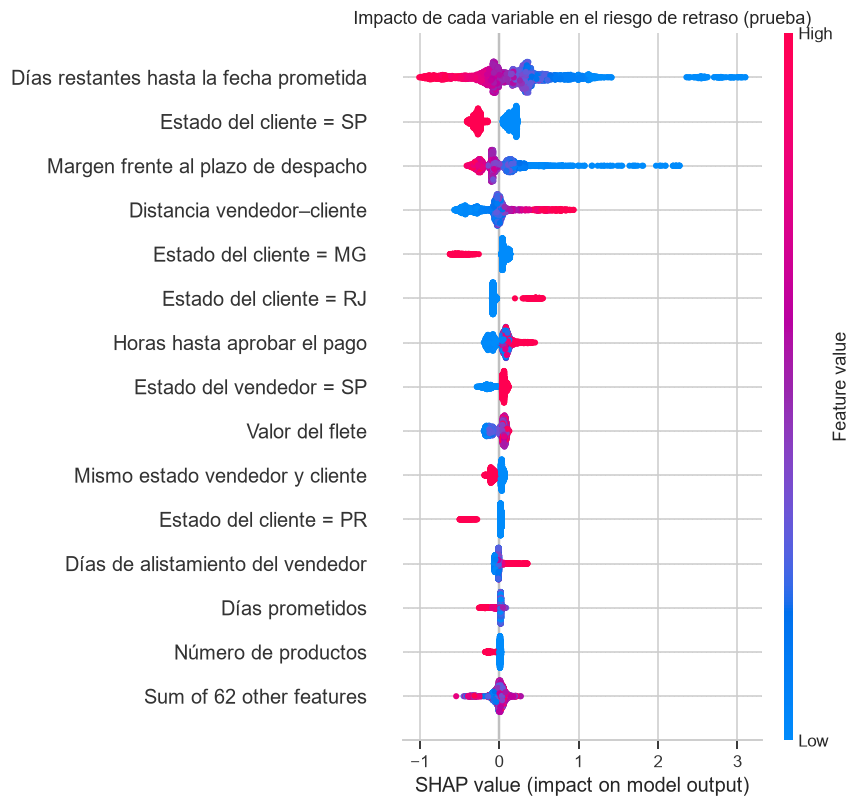

In [47]:
import shap

prep, model = final_model.named_steps["prep"], final_model.named_steps["model"]
sample = test.sample(3000, random_state=RANDOM_STATE)
Xs = pd.DataFrame(prep.transform(sample), columns=[ml.pretty_feature(n) for n in prep.get_feature_names_out()])
explainer = shap.TreeExplainer(model)
sv = explainer(Xs)
if sv.values.ndim == 3:  # modelos que devuelven una columna por clase
    sv = sv[..., 1]
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("Impacto de cada variable en el riesgo de retraso (prueba)"); plt.tight_layout(); plt.show()

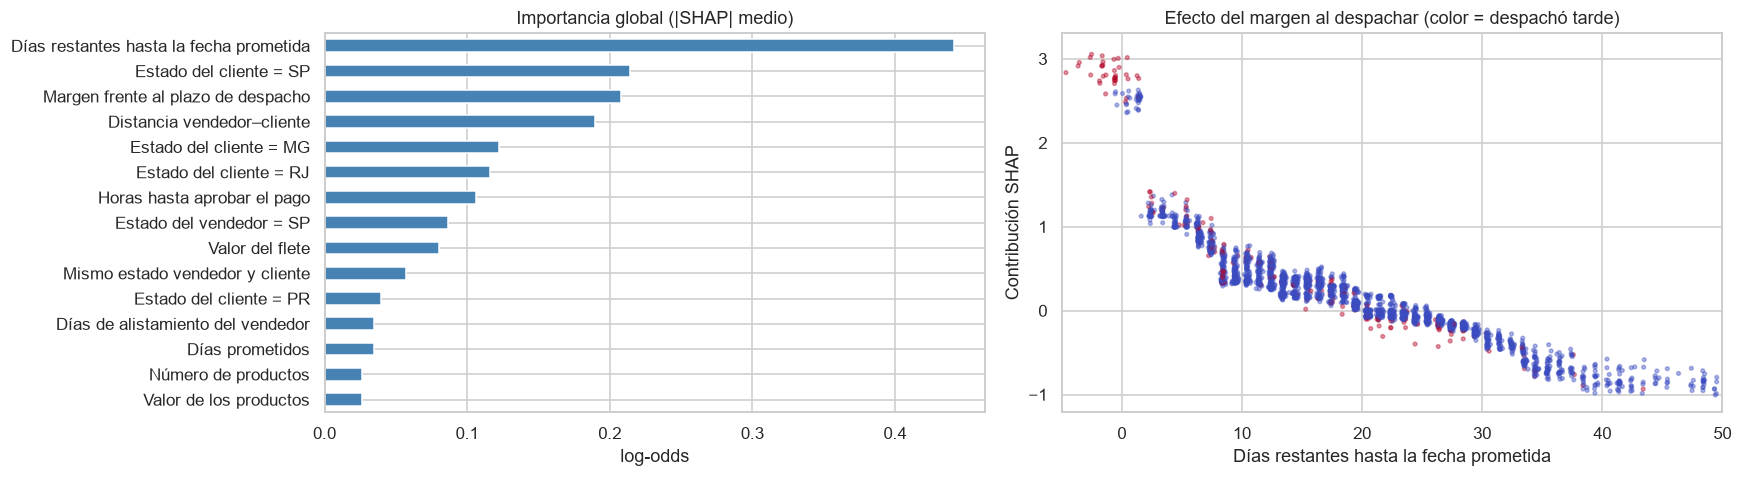

In [48]:
imp = pd.Series(np.abs(sv.values).mean(0), index=Xs.columns).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
imp.head(15)[::-1].plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set(title="Importancia global (|SHAP| medio)", xlabel="log-odds")
col = ml.LABELS["slack_at_ship"]
axes[1].scatter(sample.slack_at_ship, sv[:, col].values, s=6, alpha=.4, c=sample.shipped_after_limit, cmap="coolwarm")
axes[1].set(title="Efecto del margen al despachar (color = despachó tarde)", xlabel="Días restantes hasta la fecha prometida",
            ylabel="Contribución SHAP", xlim=(-5, 50))
plt.tight_layout(); plt.show()

Pedido de mayor riesgo en la muestra: probabilidad 94.3% | ¿llegó tarde? sí


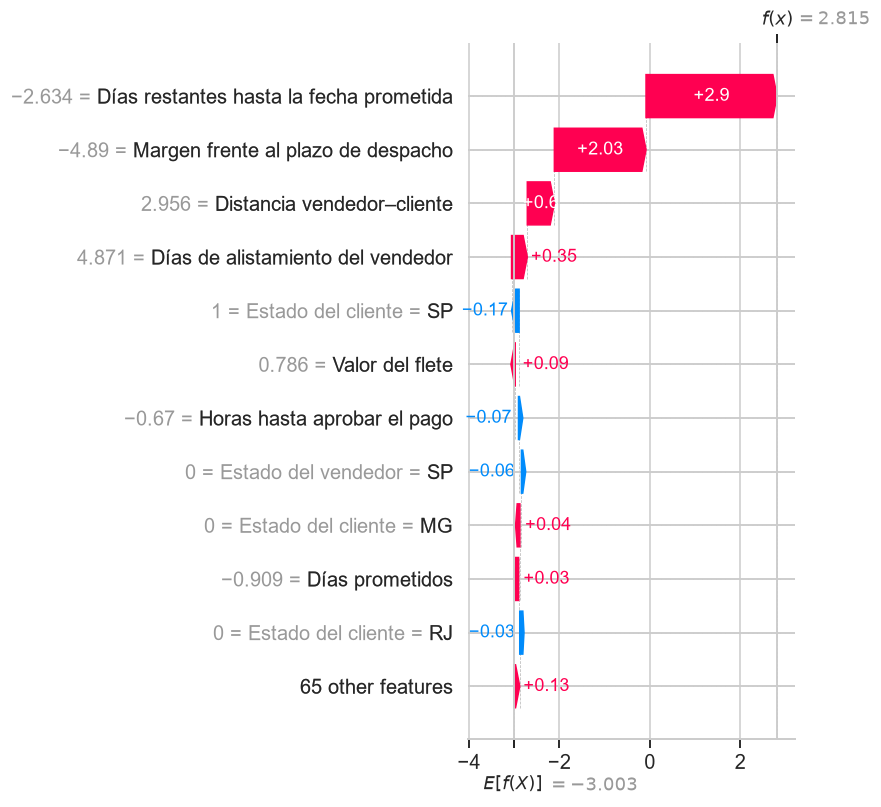

In [49]:
i = int(np.argmax(final_model.predict_proba(sample)[:, 1]))
print(f"Pedido de mayor riesgo en la muestra: probabilidad {final_model.predict_proba(sample.iloc[[i]])[0, 1]:.1%} "
      f"| ¿llegó tarde? {'sí' if sample.late.iloc[i] else 'no'}")
shap.plots.waterfall(sv[i], max_display=12, show=False)
plt.tight_layout(); plt.show()

**Lectura:**
- **La variable más importante es el margen que le queda a la transportadora al despachar** (`slack_at_ship`): con poco margen o margen negativo (la fecha prometida ya pasó o está por pasar) el riesgo se dispara. Le sigue **el margen frente al plazo de despacho del vendedor**: despachar tarde aumenta el riesgo. Las dos confirman lo visto en el EDA (5.8) y justifican el momento de predicción.
- **La geografía** pesa después: destino São Paulo (SP), Minas Gerais (MG) y Paraná (PR) reduce el riesgo, y Rio de Janeiro (RJ) lo aumenta, igual que en 5.4. Mayor distancia, más riesgo.
- **El alistamiento del vendedor** importa cuando es largo, y la aprobación lenta del pago agrega algo de riesgo.
- **Precio, peso, categoría y medio de pago** casi no influyen: el retraso es un problema logístico, no de producto.
- Todo lo que el modelo aprendió tiene sentido de negocio y nada depende de información del futuro: otra evidencia de que no hay fuga.
- **Ejemplo individual:** el pedido de mayor riesgo de la muestra (94 %, y sí llegó tarde) se despachó ya pasada la fecha prometida y casi 5 días después del plazo del vendedor; esas dos razones explican casi todo su riesgo. Es la explicación que ve el usuario en la interfaz, traducida a lenguaje natural. *(En las gráficas, los valores de las variables numéricas aparecen estandarizados.)*

## 13. Exportación del modelo y despliegue (3.8)

El despliegue es una aplicación web en **Streamlit** (`app/app.py`) pensada para el analista de operaciones, sin conocimientos técnicos:

- **Evaluar un despacho:** el analista elige el vendedor y llena los datos del pedido (fechas, valor, flete, peso, destino). La app calcula todas las variables con las mismas funciones de `src/olist_ml.py` y muestra la probabilidad de retraso, un **semáforo** (alto = dentro del 10 % de mayor riesgo; medio = dentro del 25 %), el **segmento del vendedor** y las razones principales (SHAP) en lenguaje natural.
- **Lote del día:** subir un CSV con los despachos del día y descargar la lista priorizada.
- **Ejemplos históricos:** pedidos reales del periodo de prueba para la demostración en video.

Se exporta un único archivo con todo lo necesario: el `Pipeline` evaluado en la sección 10 (preprocesamiento + modelo), los umbrales, el segmentador K-Means con sus nombres, la foto actual de los vendedores, la tabla de coordenadas y una muestra de referencia para el monitoreo de deriva. El modelo desplegado es **exactamente** el que se evaluó en prueba.

In [50]:
coords = ml.zip_coordinates(raw["geolocation"])
NOW = df.order_delivered_customer_date.max().normalize() + pd.Timedelta(days=1)
sellers_now = ml.seller_snapshot(df, NOW, PRIOR_LATE, PRIOR_BAD)
sellers_now["segment"] = ml.assign_segment(sellers_now, segmenter, SEG_NAMES)
recent = df[df.order_delivered_carrier_date >= NOW - pd.Timedelta(days=60)]
network_now = {c: float(recent[c].median()) for c in NET}

risk = pd.cut(p_test, [0, MEDIUM, THRESHOLD, 1], labels=["bajo", "medio", "alto"])
examples = pd.concat([g.sample(min(len(g), 5), random_state=RANDOM_STATE)
                      for _, g in test.assign(prob=p_test, riesgo=risk).groupby(["late", "riesgo"], observed=True)],
                     ignore_index=True)
bundle = {
    "model": final_model,
    "features": {"num": FINAL_NUM, "cat": FINAL_CAT},
    "thresholds": {"alto": THRESHOLD, "medio": MEDIUM, "capacidad": CAPACITY},
    "segmenter": segmenter, "segment_names": SEG_NAMES, "segment_profiles": profile,
    "sellers": sellers_now, "coords": coords, "network": network_now,
    "priors": {"late": PRIOR_LATE, "bad": PRIOR_BAD},
    "choices": {"category": sorted(df.category.unique()), "payment_type": sorted(df.payment_type.dropna().unique()),
                "customer_state": sorted(df.customer_state.unique()),
                "customer_zip_by_state": df.groupby("customer_state").customer_zip_code_prefix.agg(
                    lambda s: s.value_counts().index[0]).to_dict()},
    "examples": examples,
    "reference": train.sample(5000, random_state=RANDOM_STATE)[FINAL_NUM + FINAL_CAT],
    "metrics": {"test_pr_auc": average_precision_score(y_test, p_test), "test_roc_auc": roc_auc_score(y_test, p_test),
                "test_prevalence": y_test.mean(), "headline": HEADLINE, "policies": ops.to_dict()},
    "trained_until": TRAIN_END, "data_until": NOW, "version": "1.0",
}
path = MODELS / "late_delivery_model.joblib"
joblib.dump(bundle, path, compress=3)
print(f"Guardado {path} ({path.stat().st_size / 1e6:.1f} MB) | vendedores en la foto: {len(sellers_now):,} | "
      f"ejemplos: {len(examples)}")

Guardado models\late_delivery_model.joblib (1.0 MB) | vendedores en la foto: 2,935 | ejemplos: 30


**Prueba de consistencia entrenamiento ↔ interfaz.** Se reconstruye un pedido real de prueba *como lo llenaría el analista en el formulario* (con los datos crudos del producto y el perfil del vendedor en el momento de su despacho) y se verifica que la interfaz produce la misma probabilidad que el pipeline del notebook.

In [51]:
loaded = joblib.load(path)
one_item = raw["items"].groupby("order_id").filter(lambda g: len(g) == 1).order_id
o = test[test.order_id.isin(one_item)].sample(1, random_state=1).iloc[0]
item = raw["items"].set_index("order_id").loc[o.order_id]
prod = raw["products"].set_index("product_id").loc[item.product_id]
form = {
    "order_purchase_timestamp": o.order_purchase_timestamp, "order_approved_at": o.order_approved_at,
    "order_delivered_carrier_date": o.order_delivered_carrier_date,
    "order_estimated_delivery_date": o.order_estimated_delivery_date, "shipping_limit": o.shipping_limit,
    "price": item.price, "freight": item.freight_value, "weight_g": prod.product_weight_g,
    "length_cm": prod.product_length_cm, "height_cm": prod.product_height_cm, "width_cm": prod.product_width_cm,
    "n_items": 1, "photos": prod.product_photos_qty, "description_len": prod.product_description_lenght,
    "installments": o.installments, "customer_state": o.customer_state, "customer_zip_code_prefix": o.customer_zip_code_prefix,
    "seller_state": o.seller_state, "seller_zip": o.seller_zip, "category": o.category, "payment_type": o.payment_type,
}
seller_then = ml.seller_snapshot(df, o.order_delivered_carrier_date, PRIOR_LATE, PRIOR_BAD).loc[o.seller_id]
row = ml.features_from_form(form, seller_then, loaded["coords"],
                            {"net_late_rate_28d": o.net_late_rate_28d, "net_backlog_ratio": o.net_backlog_ratio})
p_nb = final_model.predict_proba(test[test.order_id == o.order_id])[0, 1]
p_app = loaded["model"].predict_proba(row)[0, 1]
print(f"Probabilidad en el notebook: {p_nb:.6f} | en la interfaz: {p_app:.6f}")
assert abs(p_nb - p_app) < 1e-6, "La interfaz no reproduce el pipeline"

Probabilidad en el notebook: 0.044544 | en la interfaz: 0.044544


**Cómo usar la interfaz:**

```bash
pip install -r requirements.txt
streamlit run app/app.py
```

Se abre en el navegador (`http://localhost:8501`). Para publicarla en internet sin servidor propio se puede usar **Streamlit Community Cloud**: se conecta el repositorio de GitHub, se elige `app/app.py` como archivo principal y queda una URL pública. El archivo `models/late_delivery_model.joblib` debe estar en el repositorio (pesa pocos MB; los datos crudos no son necesarios para la app).

## 14. Estrategia de reajuste (3.9)

Un modelo de retrasos se degrada por dos razones que ya vimos en los datos: **cambia el entorno** (temporadas, huelgas, nuevas transportadoras) y **cambia la mezcla de pedidos** (nuevos vendedores, categorías, regiones). La estrategia tiene cuatro partes: detectar, decidir, validar y desplegar. Primero se mide con los propios datos.

### 14.1 Detección de deriva en los datos: PSI

El **Population Stability Index** compara la distribución de cada variable en producción frente a la de entrenamiento: PSI < 0.1 estable; 0.1–0.25 cambio moderado (vigilar); > 0.25 cambio fuerte (investigar / reentrenar). No necesita esperar a conocer las etiquetas, así que es una alarma temprana.

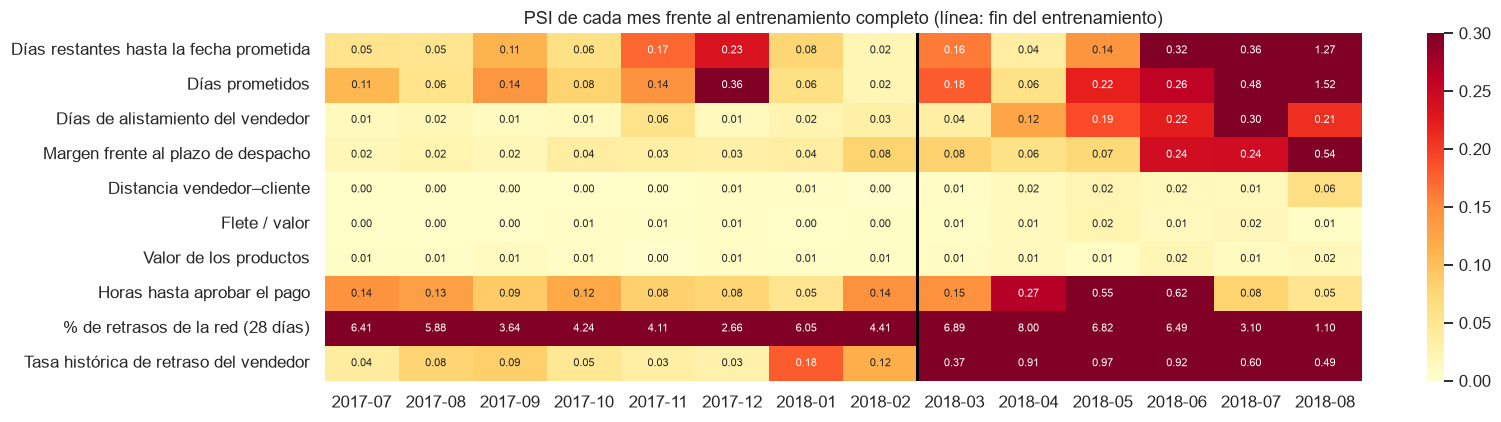

purchase_month,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
promised_days,22.3,27.4,25.6,24.3,21.3,23.4,21.5,27.3,19.3,13.4
slack_at_ship,19.1,24.1,22.2,20.6,18.3,21.0,19.4,24.6,16.4,11.4
approval_hours,0.4,0.3,0.3,0.4,0.3,0.5,0.5,0.4,0.5,0.3


In [52]:
key_vars = [v for v in ["slack_at_ship", "promised_days", "handling_days", "limit_margin_days", "distance_km",
                        "freight_ratio", "price", "approval_hours", "net_late_rate_28d", "seller_late_rate"] if v in df]
months = pd.period_range("2017-07", "2018-08", freq="M")
psi_table = pd.DataFrame({str(m): {v: ml.psi(train[v], df.loc[df.purchase_month == m, v]) for v in key_vars}
                          for m in months})
fig, ax = plt.subplots(figsize=(15, 4))
sns.heatmap(psi_table.rename(index=ml.LABELS), cmap="YlOrRd", vmin=0, vmax=0.3, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax)
ax.axvline(list(psi_table.columns).index("2018-03"), color="black", lw=2)
ax.set(title="PSI de cada mes frente al entrenamiento completo (línea: fin del entrenamiento)")
plt.tight_layout(); plt.show()
df[df.purchase_month >= pd.Period("2017-11", "M")].groupby("purchase_month")[
    ["promised_days", "slack_at_ship", "approval_hours"]].median().round(1).T

### 14.2 Detección de degradación del desempeño y simulación del reajuste

Cuando llegan las fechas reales de entrega se puede medir el desempeño. Se simula la operación: el **modelo estático** (entrenado una vez con datos hasta feb-2018) frente a una política de **reentrenamiento mensual** con ventana creciente. Cada mes se reentrena con lo que *se conocía* el primer día del mes (compras hasta dos meses antes y ya entregadas), igual que en producción.

In [53]:
rows = []
for m in pd.period_range("2018-05", "2018-08", freq="M"):
    start = m.to_timestamp()
    tr = df[(df.order_purchase_timestamp < start - pd.DateOffset(months=2)) & (df.order_delivered_customer_date < start)]
    te = df[df.purchase_month == m]
    challenger = clone(final_model).fit(tr, tr.late)
    p_static, p_new = final_model.predict_proba(te)[:, 1], challenger.predict_proba(te)[:, 1]
    # Recalibración del umbral sin etiquetas: percentil 90 de los despachos de los 30 días anteriores
    last30 = df[(df.order_delivered_carrier_date >= start - pd.Timedelta(days=30)) & (df.order_delivered_carrier_date < start)]
    thr_m = np.quantile(final_model.predict_proba(last30)[:, 1], 1 - CAPACITY)
    late_m = te.late.values == 1
    rows.append({"mes": str(m), "pedidos entrenamiento": len(tr), "prevalencia": te.late.mean(),
                 "PR-AUC estático": average_precision_score(te.late, p_static),
                 "PR-AUC reentrenado": average_precision_score(te.late, p_new),
                 "% marcados (umbral fijo)": (p_static >= THRESHOLD).mean(),
                 "% marcados (umbral recalibrado)": (p_static >= thr_m).mean(),
                 "recall (umbral fijo)": (p_static[late_m] >= THRESHOLD).mean(),
                 "recall (umbral recalibrado)": (p_static[late_m] >= thr_m).mean()})
retrain_sim = pd.DataFrame(rows).set_index("mes")
retrain_sim.round(3)

,pedidos entrenamiento,prevalencia,PR-AUC estático,PR-AUC reentrenado,% marcados (umbral fijo),% marcados (umbral recalibrado),recall (umbral fijo),recall (umbral recalibrado)
mes,,,,,,,,
2018-05,56991,0.066,0.314,0.315,0.093,0.104,0.393,0.411
2018-06,64021,0.012,0.156,0.141,0.041,0.042,0.352,0.352
2018-07,70822,0.034,0.463,0.457,0.168,0.314,0.635,0.736
2018-08,77576,0.062,0.578,0.554,0.231,0.177,0.718,0.697


**Lectura de 14.1 y 14.2:**
- **El PSI detecta el cambio a tiempo.** Las variables de la promesa (`slack_at_ship`, `promised_days`, margen de despacho) estuvieron estables en el entrenamiento (PSI < 0.25 casi todos los meses) y se disparan en jun–ago 2018 (PSI 0.3 a 1.5): Olist **acortó sus promesas de entrega** de ~24 a ~13 días. Con la regla de 14.3, la alerta roja habría saltado en junio, antes de que nadie midiera el desempeño.
- **Dos variables candidatas tienen PSI alto incluso dentro del entrenamiento** (congestión de la red y tasa histórica del vendedor). Cambian de nivel con el tiempo por construcción (acumulan los picos de retraso). Es otro argumento para haberlas dejado fuera del modelo (9.3): habrían disparado alarmas permanentes.
- **Reentrenar no mejoró el desempeño en este periodo.** El modelo reentrenado cada mes con todo lo disponible obtiene prácticamente la misma PR-AUC que el estático (diferencias de ±0.02). El **orden** que produce el modelo se mantiene (ROC-AUC estable); lo que cambia es el **nivel** de los puntajes.
- **Recalibrar el umbral con los últimos 30 días tampoco basta** cuando el cambio es brusco: en julio marca el 31 % de los despachos porque se calibró con junio, un mes de promesas largas. En cambio, la lista diaria por ranking (política C de la sección 11) se mantuvo en 9–11 % todos los meses.
- **Conclusión:** la primera defensa contra la deriva es operar con **ranking diario** (inmune a cambios de nivel); el monitoreo de PSI y de desempeño decide **cuándo reentrenar**, y el reentrenamiento se acepta solo si mejora al modelo actual (*champion vs. challenger*). En este periodo, esa regla habría mantenido el modelo actual, que es lo correcto según la simulación.

### 14.3 Política de reajuste propuesta

| Componente | Qué se hace | Criterio / frecuencia |
|---|---|---|
| **Monitoreo de datos (sin esperar etiquetas)** | PSI semanal de las 10 variables clave y del puntaje del modelo frente a la muestra de referencia guardada en el modelo | Alerta amarilla si alguna variable clave supera PSI 0.1 dos semanas seguidas; roja si supera 0.25 |
| **Monitoreo operativo** | % de despachos marcados como riesgo alto | Si se aleja más de ±50 % del 10 % de diseño (p. ej. < 5 % o > 15 %), el umbral ya no corresponde a la capacidad del equipo |
| **Lista diaria por ranking** | La lista de revisión es siempre el 10 % de despachos de mayor riesgo del día, no un corte fijo de probabilidad | Diaria; es inmune a cambios de nivel de los puntajes (14.2) |
| **Recalibración del umbral del semáforo (sin etiquetas)** | Recalcular el umbral de riesgo alto como el percentil 90 de los despachos de los últimos 30 días | Semanal y automática; ante una alerta roja de PSI, recalcular con los últimos 7 días |
| **Monitoreo de desempeño (con etiquetas)** | Cada mes, cuando ya se entregaron los pedidos del mes anterior: PR-AUC, recall y precisión en el umbral | Alerta si la PR-AUC cae más de 20 % frente a la validación, o si el recall en el umbral cae más de 10 puntos, dos meses seguidos |
| **Reentrenamiento programado** | Reentrenar con ventana creciente (todo lo entregado hasta la fecha), recalcular el umbral con validación temporal y actualizar la foto de vendedores | **Mensual** para el modelo; **trimestral** para la segmentación (los perfiles de vendedores cambian más lento) |
| **Reentrenamiento por alerta** | Si hay alerta roja de PSI o de desempeño, se adelanta el reentrenamiento | Inmediato |
| **Validación del nuevo modelo (champion vs. challenger)** | El candidato y el modelo en producción se evalúan sobre el último mes con etiquetas, que ninguno de los dos vio | Se reemplaza solo si mejora la PR-AUC y no empeora el recall en el umbral; además se repiten las pruebas de fuga de la sección 10.1 |
| **Puesta en producción** | Dos semanas en modo sombra (el candidato puntúa pero no se muestra), luego reemplazo; se guarda la versión anterior | Rollback inmediato si el % de marcados o las quejas del equipo se disparan |
| **Versionado** | Cada modelo se guarda con fecha de corte, métricas y versión en `models/` | Trazabilidad para la auditoría |

## 15. Conclusiones

1. **Problema y datos.** Se construyó, a partir de las 9 tablas del dataset oficial de Olist en Kaggle, un modelo que estima al momento del despacho el riesgo de que un pedido llegue después de la fecha prometida. Ese es el momento en que ya se conoce el desempeño del vendedor en el pedido (las variables más importantes según SHAP) y todavía hay tiempo de actuar.
2. **No supervisado.** La segmentación de vendedores (K-Means, k = 5, contrastada con clustering jerárquico, DBSCAN y PCA) produce cinco perfiles interpretables y estables en el tiempo. El segmento "Lentos y con quejas" tiene el doble de retrasos tanto en entrenamiento como en prueba. DBSCAN aporta una lista de 18 vendedores atípicos a revisar.
3. **De no supervisado a supervisado.** Se probó con validación cruzada si el segmento o el perfil del vendedor mejoran la predicción. No lo hacen de forma consistente, porque el modelo ya ve el comportamiento del vendedor en el propio despacho. Por eso el modelo final no los usa, y la segmentación se usa donde sí aporta: como herramienta de negocio en la interfaz.
4. **Supervisado.** Gradient Boosting y SVM empatan en validación temporal; se eligió Gradient Boosting por entregar probabilidades y explicaciones exactas con SHAP. El data augmentation (SMOTENC, CTGAN) y los pesos de clase no mejoraron y distorsionaron las probabilidades, así que se descartaron con evidencia.
5. **Generalización.** En datos futuros nunca vistos (may–ago 2018) el modelo alcanza PR-AUC 0.39 (9 veces el azar) y ROC-AUC 0.82, estable mes a mes. Las pruebas de etiquetas barajadas, de fuga intencional y de validación aleatoria muestran que el resultado no viene de fuga ni de sobreajuste.
6. **Uso real.** Revisando el 10 % de despachos de mayor riesgo cada día, el equipo encuentra 1 retraso por cada 5 revisiones (5 veces mejor que al azar) y cubre casi la mitad de todos los retrasos. La interfaz en Streamlit permite usarlo sin conocimientos técnicos y explica cada alerta.
7. **Mantenimiento.** Los propios datos mostraron un cambio de política (Olist acortó sus promesas en 2018) que el PSI detecta a tiempo. La estrategia combina lista diaria por ranking, monitoreo de deriva y de desempeño, y reentrenamiento validado contra el modelo actual.

**Limitaciones y trabajo futuro:** el dataset no incluye la transportadora ni eventos de rastreo, que probablemente son la mayor fuente de información sobre retrasos; tampoco cubre periodos posteriores a 2018. Con esos datos se podría reestimar el riesgo en cada escaneo del paquete y no solo en el despacho.

In [54]:
print(f"Tiempo total de ejecución: {(time.time() - T0) / 60:.1f} minutos")

Tiempo total de ejecución: 11.4 minutos
